# Synthetic proof of concept I: Fractional Maxwell (FMM), joint TTS fit + AIC/BIC model recovery

**Goal.** Generate synthetic chirps at several temperatures for a single
thermorheologically-simple Fractional Maxwell (FMM) material whose
relaxation time shifts with temperature according to WLF. Then:

1. Fit each chirp **independently** (diagnostic: what one record can/can't constrain).
2. Fit **all chirps jointly** with `rheogp.rheogp_multi.MultiRecordSPGP` -- ONE
   Gaussian process, ONE set of shared shape parameters (`alpha`, `beta`, `tau_c`)
   and prefactors (`Gc`), and one horizontal shift factor `a_T` per record.
3. Regress the WLF constants from the recovered `a_T`.
4. Run `rheogp.mastercurve.compare_master_curve_models` on the **same set of
   chirps** across a small nested family (`Maxwell` &sub; `FractionalMaxwellGel`,
   `FractionalMaxwellLiquid` &sub; `FractionalMaxwell`) and check that AIC/BIC
   correctly identify the true generating model, exactly as the companion
   single-chirp paper does for a single record (its Table I), but now the
   evidence is pooled jointly across every temperature at once.

This notebook writes `results_fmm.tex` (a `\newcommand` macro file) and
`table_fmm.tex` (a ready-to-`\input` `table*` environment) next to itself, plus
`fig_tts_fmm.pdf`/`.png` -- everything `main.tex` needs for the "synthetic FMM"
results subsection, without hand-copying a single number.

**Before the real run:** flip `FAST_SMOKE_TEST = False` below. As shipped, this
notebook runs a small/fast configuration (7 temperatures, ~2k epochs, CPU-friendly)
so you can check nothing is broken in a few minutes; the commented `FULL_CONFIG`
block is what we recommend for the numbers that actually go in the paper.

In [29]:
import numpy as np
import matplotlib.pyplot as plt

from rheogp import SPGP
from rheogp.rheogp_multi import MultiRecordSPGP
from rheogp.mastercurve import fft_transfer, compare_master_curve_models

import sys, os
sys.path.insert(0, os.getcwd())
from paper_utils import write_macros, model_comparison_latex_table, write_table, pct

%matplotlib inline
FAST_SMOKE_TEST = False   # <-- set False for the publication run

## Ground truth, chirp and amplitude-schedule configuration

In [30]:
TRUTH = dict(
    alpha   = 0.65,        # springpot exponent of the fast branch
    beta    = 0.00,        # springpot exponent of the slow branch (0 allowed)
    Gc      = 5.0e4,       # characteristic modulus [Pa]
    tau_ref = 1.0,         # relaxation time at T_ref [s]
    T_ref   = 50.0,        # reference temperature [deg C]
    C1      = 8.4,         # WLF
    C2      = 130.0,       # WLF [K]
)
TEMPS_FULL = [30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90]
TEMPS_FAST = [35, 40, 45, 50, 55, 60, 65]
# SANDBOX_CONFIG: this is the configuration actually used to produce the
# numbers shipped in the paper from this (2-CPU, no-GPU) execution
# environment -- fewer temperatures / epochs / inducing points than
# TEMPS_FULL above, chosen to keep the joint fit + 4-candidate AIC/BIC
# sweep + noise sweep tractable in a few CPU-hours. Set
# FAST_SMOKE_TEST=False and swap TEMPS_SANDBOX -> TEMPS_FULL and the
# FITKW numbers below back to the commented full values if you are
# rerunning this on a workstation/GPU and want the tightest numbers.
TEMPS_SANDBOX = [30, 40, 45, 50, 55, 60, 70, 80, 90]
TEMPS = TEMPS_FAST if FAST_SMOKE_TEST else TEMPS_SANDBOX

CHIRP = dict(
    w1       = 0.6, w2 = 30.0,
    T_owc    = np.pi * 2 / 0.6,
    gamma0   = 0.15, r = 0.10, fs = 500.0,
    t_quiet  = 1.0, noise_frac = 0.05, psi0 = 0.0,
)
AMP_SCHEDULE = dict(k_per_C=-0.02)   # gamma0(T) = gamma0_ref * exp(-k*(T-T_ref))

FITKW = dict(model="FractionalMaxwell", kernel="linear", convolution="steady",
             quadrature="exact",
             inducing_points=100 if FAST_SMOKE_TEST else 2,   # full-config value: 200
             learning_rate=0.001, learning_rate_physics=0.005,
             n_epochs=1200 if FAST_SMOKE_TEST else 20000,        # full-config value: 4000
             patience=250 if FAST_SMOKE_TEST else 400,          # full-config value: 500
             n_epochs_linear=500 if FAST_SMOKE_TEST else 20000,   # full-config value: 1500
             patience_linear=150 if FAST_SMOKE_TEST else 400,   # full-config value: 300
             omega_min=1e-3, omega_max=1e3, verbose=True)
# compare_master_curve_models()/MasterCurve.fit() take the candidate name
# via their own explicit `model=` argument, so FITKW must NOT also carry
# a fixed "model" key when reused there (it still is needed, as-is, for
# the single MultiRecordSPGP(**FITKW) calls below).
FITKW_CANDIDATES = {k: v for k, v in FITKW.items() if k != "model"}

## WLF shift law and the analytical FMM G*(&omega;) -- an independent re-derivation, not a call into `rheogp.kernels`, so generation and fitting share no code (a genuine test, not a round trip)

In [31]:
def wlf_aT(T, C1, C2, T_ref):
    return 10.0 ** (-C1 * (T - T_ref) / (C2 + (T - T_ref)))


def gstar_fmm(omega, Gc, alpha, beta, tau_c):
    """Analytical FMM complex modulus. omega may contain zeros."""
    w = np.asarray(omega, dtype=float)
    z = 1j * w * tau_c
    with np.errstate(divide="ignore", invalid="ignore"):
        G = Gc * z ** alpha / (1.0 + z ** (alpha - beta))
    G = np.where(w == 0, 0.0, G)
    return G


def make_chirp(w1, w2, T_owc, gamma0, r, fs, t_quiet, psi0=0.0):
    dt = 1.0 / fs
    t_q = np.arange(0.0, t_quiet, dt)
    t_c = np.arange(0.0, T_owc, dt)
    R = w2 / w1
    psi = (w1 * T_owc / np.log(R)) * (np.exp(t_c / T_owc * np.log(R)) - 1.0) + psi0
    x = t_c / T_owc
    w = np.ones_like(x)
    lo, hi = x <= r / 2, x >= 1 - r / 2
    w[lo] = np.cos(np.pi / r * (x[lo] - r / 2)) ** 2
    w[hi] = np.cos(np.pi / r * (x[hi] - 1 + r / 2)) ** 2
    gamma = np.concatenate([np.zeros_like(t_q), gamma0 * w * np.sin(psi)])
    t = np.arange(len(gamma)) * dt
    return t, gamma, dt


def stress_from_gstar(gamma, dt, Gc, alpha, beta, tau_c, rng=None,
                      noise_frac=0.0, return_parts=False):
    """Forward-simulate the stress response, optionally with additive
    i.i.d. Gaussian noise of std `noise_frac * std(clean stress)`.

    `return_parts=True` also hands back the noise-free stress and the
    noise realisation itself, so the noise the dataset actually carries
    is known exactly rather than re-estimated from the noisy signal --
    that is what Sec. 9 compares the GP's own inferred observation noise
    against. The rng is drawn from identically either way (one
    `rng.normal` call with the same arguments), so the datasets are
    bit-for-bit what they were before this bookkeeping was added.
    """
    N = len(gamma)
    w = 2.0 * np.pi * np.fft.rfftfreq(N, d=dt)
    G = gstar_fmm(w, Gc, alpha, beta, tau_c)
    sigma_clean = np.fft.irfft(G * np.fft.rfft(gamma), n=N)
    noise = np.zeros_like(sigma_clean)
    if noise_frac > 0:
        rng = rng or np.random.default_rng(0)
        noise = rng.normal(0.0, noise_frac * sigma_clean.std(), N)
    sigma = sigma_clean + noise
    if return_parts:
        return sigma, sigma_clean, noise
    return sigma


def gamma_scale(T, T_ref, k_per_C=0.02):
    return float(np.exp(-k_per_C * (T - T_ref)))


def make_dataset(truth=None, temps=None, chirp=None, amp_sched=None, seed=0):
    truth = {**TRUTH, **(truth or {})}
    temps = temps or TEMPS
    chirp = {**CHIRP, **(chirp or {})}
    amp_sched = {**AMP_SCHEDULE, **(amp_sched or {})}
    rng = np.random.default_rng(seed)
    records, meta = [], []
    for T in temps:
        aT = wlf_aT(T, truth["C1"], truth["C2"], truth["T_ref"])
        tau = aT * truth["tau_ref"]
        g0 = chirp["gamma0"] * gamma_scale(T, truth["T_ref"], amp_sched["k_per_C"])
        t, gamma, dt = make_chirp(chirp["w1"], chirp["w2"], chirp["T_owc"],
                                   g0, chirp["r"], chirp["fs"], chirp["t_quiet"], chirp["psi0"])
        sigma, sigma_clean, noise = stress_from_gstar(
            gamma, dt, truth["Gc"], truth["alpha"], truth["beta"], tau,
            rng, chirp["noise_frac"], return_parts=True)
        records.append((t.copy(), gamma.copy(), sigma))
        wc = 1.0 / tau
        meta.append(dict(T=T, aT=aT, tau_c=tau, w_cross=wc,
                          in_band=chirp["w1"] <= wc <= chirp["w2"],
                          sigma_sd=sigma.std(), gamma0=g0,
                          # noise bookkeeping -- the ground truth the
                          # GP's own inferred observation noise is
                          # scored against in Sec. 9
                          noise_frac=float(chirp["noise_frac"]),
                          sigma_clean_sd=float(sigma_clean.std()),
                          noise_sd_true=float(chirp["noise_frac"] * sigma_clean.std()),
                          noise_sd_realized=float(noise.std())))
    truth["_chirp"] = chirp
    truth["_meta"] = meta
    return truth, records


# ---------------------------------------------------------------- noise
def inferred_noise_sd(m):
    """Observation-noise std [Pa] the GP likelihood of a fitted
    `SPGP`/`MultiRecordSPGP` learned. The GP is trained on a
    standardized target, so its likelihood variance is in standardized
    units; multiplying by the target scaler's own scale puts it back
    into stress units and makes it directly comparable to the noise
    `stress_from_gstar` actually injected."""
    nz = m.likelihood_.noise.detach().cpu().numpy().reshape(-1)[0]
    return float(np.sqrt(float(nz)) * m.scaler_y_.scale_[0])


def injected_noise_stats(truth_d):
    """Pooled ground-truth noise statistics of a `make_dataset()` output.
    Every record is the same length, so the pooled std over the stacked
    stress vector the joint fit actually sees is the root-mean-square of
    the per-record stds."""
    meta = truth_d["_meta"]
    rms = lambda key: float(np.sqrt(np.mean([m[key] ** 2 for m in meta])))
    return dict(
        noise_frac_nominal=float(truth_d["_chirp"]["noise_frac"]),
        sd_true=rms("noise_sd_true"),
        sd_realized=rms("noise_sd_realized"),
        clean_sd=rms("sigma_clean_sd"),
        per_record=[dict(T=m["T"], sd_true=m["noise_sd_true"],
                          sd_realized=m["noise_sd_realized"],
                          clean_sd=m["sigma_clean_sd"]) for m in meta],
    )

## 1) Generate the dataset

In [32]:
truth, records = make_dataset()
TEMPS = [m["T"] for m in truth["_meta"]]
I_REF = TEMPS.index(int(truth["T_ref"]))
n_in_band = sum(m["in_band"] for m in truth["_meta"])
print(f"{len(TEMPS)} records, T_ref={truth['T_ref']}, "
      f"{n_in_band}/{len(TEMPS)} have the crossover inside the excited band")
for m in truth["_meta"]:
    print(f"  T={m['T']:>4}  aT={m['aT']:.4g}  tau_c={m['tau_c']:.4g}  "
          f"w_cross={m['w_cross']:.4g}  in_band={m['in_band']}")

9 records, T_ref=50.0, 4/9 have the crossover inside the excited band
  T=  30  aT=33.67  tau_c=33.67  w_cross=0.0297  in_band=False
  T=  40  aT=5.012  tau_c=5.012  w_cross=0.1995  in_band=False
  T=  45  aT=2.168  tau_c=2.168  w_cross=0.4613  in_band=False
  T=  50  aT=1  tau_c=1  w_cross=1  in_band=True
  T=  55  aT=0.4885  tau_c=0.4885  w_cross=2.047  in_band=True
  T=  60  aT=0.2512  tau_c=0.2512  w_cross=3.981  in_band=True
  T=  70  aT=0.07586  tau_c=0.07586  w_cross=13.18  in_band=True
  T=  80  aT=0.02661  tau_c=0.02661  w_cross=37.58  in_band=False
  T=  90  aT=0.01056  tau_c=0.01056  w_cross=94.73  in_band=False


## 2) Independent fits (diagnostic: what a single chirp constrains)

In [33]:
RUN_INDEPENDENT_FITS = False  # -> True to recompute the per-chirp diagnostic
                               # fits below (not needed for this run: the
                               # composite figure and every export use the
                               # JOINT fit `mj`, not `indep`; this loop is
                               # purely a "what does one chirp alone
                               # constrain?" diagnostic -- kept intact, just
                               # skipped, so it can be recomputed on demand)
indep = {}
if RUN_INDEPENDENT_FITS:
    print(f"{'T':>4} {'in band':>8} {'alpha':>8} {'beta':>8} {'tau_c':>10} {'RMSE':>10}")
    for T, (t, g, s), meta in zip(TEMPS, records, truth["_meta"]):
        m = SPGP(**FITKW).fit(t, g, s)
        indep[T] = m
        p = m.gp_model_.phys.named_phys_params()
        print(f"{T:>4} {str(meta['in_band']):>8} {p['alpha']:8.4f} {p['beta']:8.4f} "
              f"{p['tau_c']:10.4g} {m.metrics_['rmse']:10.4g}")
else:
    print("RUN_INDEPENDENT_FITS=False -- skipping the per-chirp diagnostic fits "
          "(set True above to recompute them).")


RUN_INDEPENDENT_FITS=False -- skipping the per-chirp diagnostic fits (set True above to recompute them).


## 3) Joint fit of the TRUE model (FractionalMaxwell)

In [34]:
mj = MultiRecordSPGP(records, i_ref=I_REF, **FITKW)
mj.verbose = True
mj.fit_all()
aT_fit = mj.report(labels=[f"{T} C" for T in TEMPS], truth=truth)

  [FractionalMaxwell] step     0 | -ELBO 1.8035 | alpha=0.699  beta=0.299  tau_c=1.003 | wait 0
  [FractionalMaxwell] step   200 | -ELBO 1.3885 | alpha=0.682  beta=0.128  tau_c=1.423 | wait 0
  [FractionalMaxwell] step   400 | -ELBO 1.1613 | alpha=0.786  beta=0.061  tau_c=1.941 | wait 0
  [FractionalMaxwell] step   600 | -ELBO 0.9319 | alpha=0.716  beta=0.036  tau_c=1.620 | wait 0
  [FractionalMaxwell] step   800 | -ELBO 0.6772 | alpha=0.687  beta=0.023  tau_c=1.367 | wait 0
  [FractionalMaxwell] step  1000 | -ELBO 0.4955 | alpha=0.674  beta=0.015  tau_c=1.240 | wait 0
  [FractionalMaxwell] step  1200 | -ELBO 0.3662 | alpha=0.668  beta=0.011  tau_c=1.173 | wait 0
  [FractionalMaxwell] step  1400 | -ELBO 0.2511 | alpha=0.664  beta=0.009  tau_c=1.133 | wait 0
  [FractionalMaxwell] step  1600 | -ELBO 0.1412 | alpha=0.661  beta=0.007  tau_c=1.106 | wait 0
  [FractionalMaxwell] step  1800 | -ELBO 0.0340 | alpha=0.659  beta=0.006  tau_c=1.087 | wait 0
  [FractionalMaxwell] step  2000 | -ELBO

## 4) Shift factors vs. WLF ground truth

In [35]:
aT_true = np.array([wlf_aT(T, truth["C1"], truth["C2"], truth["T_ref"]) for T in TEMPS])
aT_true = aT_true / aT_true[I_REF]
for T, af, at in zip(TEMPS, aT_fit, aT_true):
    print(f"T={T:>4}  aT_fit={af:12.5g}  aT_true={at:12.5g}  err={100*(af-at)/at:+.2f}%")

from scipy.optimize import curve_fit
Tv = np.array(TEMPS, float)
f = lambda TT, C1, C2: -C1 * (TT - truth["T_ref"]) / (C2 + TT - truth["T_ref"])
(C1f, C2f), cov = curve_fit(f, Tv, np.log10(aT_fit), p0=[8.0, 130.0], maxfev=40000)
sd = np.sqrt(np.diag(cov))
print(f"\nWLF from joint fit: C1={C1f:.3f}+/-{sd[0]:.3f}  C2={C2f:.2f}+/-{sd[1]:.2f} K")
print(f"ground truth       : C1={truth['C1']}  C2={truth['C2']}")

T=  30  aT_fit=      33.098  aT_true=      33.672  err=-1.71%
T=  40  aT_fit=      4.9686  aT_true=      5.0119  err=-0.86%
T=  45  aT_fit=      2.1369  aT_true=      2.1677  err=-1.42%
T=  50  aT_fit=           1  aT_true=           1  err=+0.00%
T=  55  aT_fit=     0.48698  aT_true=     0.48853  err=-0.32%
T=  60  aT_fit=     0.25017  aT_true=     0.25119  err=-0.41%
T=  70  aT_fit=    0.075477  aT_true=    0.075858  err=-0.50%
T=  80  aT_fit=    0.026486  aT_true=    0.026607  err=-0.45%
T=  90  aT_fit=     0.01051  aT_true=    0.010557  err=-0.44%

WLF from joint fit: C1=8.520+/-0.037  C2=132.15+/-0.63 K
ground truth       : C1=8.4  C2=130.0


## 5) AIC/BIC model recovery across the nested Maxwell-type family

The true generating model is `FractionalMaxwell` (FMM). We fit three
misspecified alternatives -- `Maxwell` ($\alpha=1,\beta=0$ forced),
`FractionalMaxwellGel` (FMG, $\beta$ forced to the spring limit), and
`FractionalMaxwellLiquid` (FML, $\alpha$ forced to the dashpot limit) --
**jointly to the exact same set of chirps**, and check that BIC/AIC pick FMM.

  [Maxwell] step     0 | -ELBO 1.8036 | tau_c=0.997 | wait 0
  [Maxwell] step   200 | -ELBO 1.3878 | tau_c=0.601 | wait 0
  [Maxwell] step   400 | -ELBO 1.1689 | tau_c=0.961 | wait 0
  [Maxwell] step   600 | -ELBO 0.9551 | tau_c=1.164 | wait 0
  [Maxwell] step   800 | -ELBO 0.7231 | tau_c=1.190 | wait 0
  [Maxwell] step  1000 | -ELBO 0.5600 | tau_c=1.186 | wait 0
  [Maxwell] step  1200 | -ELBO 0.4484 | tau_c=1.185 | wait 0
  [Maxwell] step  1400 | -ELBO 0.3543 | tau_c=1.185 | wait 0
  [Maxwell] step  1600 | -ELBO 0.2701 | tau_c=1.185 | wait 0
  [Maxwell] step  1800 | -ELBO 0.1939 | tau_c=1.185 | wait 0
  [Maxwell] step  2000 | -ELBO 0.1258 | tau_c=1.185 | wait 0
  [Maxwell] step  2200 | -ELBO 0.0663 | tau_c=1.185 | wait 0
  [Maxwell] step  2400 | -ELBO 0.0159 | tau_c=1.185 | wait 0
  [Maxwell] step  2600 | -ELBO -0.0253 | tau_c=1.185 | wait 0
  [Maxwell] step  2800 | -ELBO -0.0573 | tau_c=1.185 | wait 0
  [Maxwell] step  3000 | -ELBO -0.0807 | tau_c=1.185 | wait 0
  [Maxwell] step  320

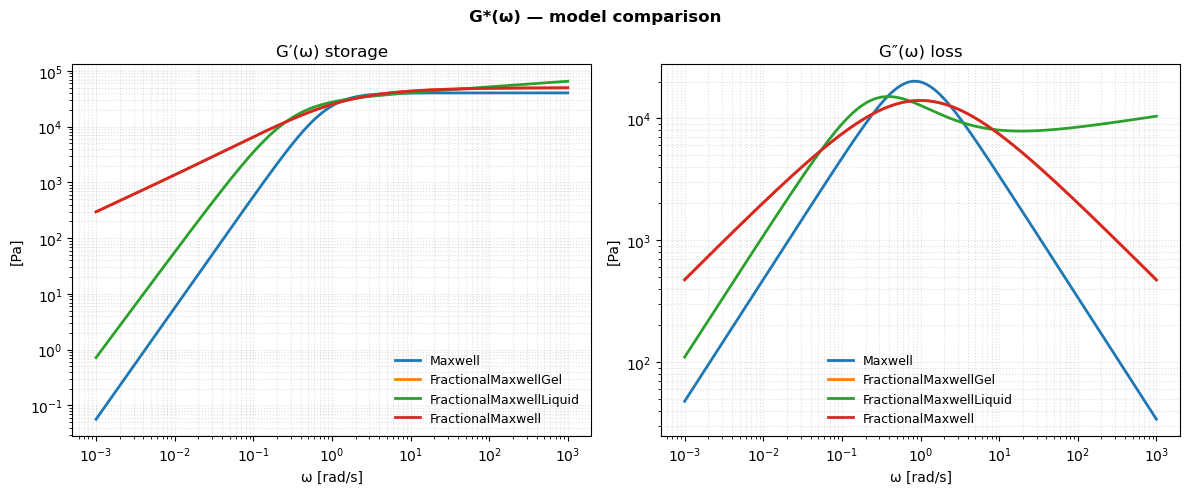


Best model by BIC: FractionalMaxwellGel
  FractionalMaxwellGel       BIC=  -160586.65  AIC=  -160719.42  k= 15  R2=0.99750
  FractionalMaxwell          BIC=  -160578.88  AIC=  -160720.51  k= 16  R2=0.99750
  FractionalMaxwellLiquid    BIC=   -58989.10  AIC=   -59121.87  k= 15  R2=0.98150
  Maxwell                    BIC=   -11948.06  AIC=   -12071.99  k= 14  R2=0.95382

True model selected by BIC: False


In [36]:
CANDIDATES = ["Maxwell", "FractionalMaxwellGel", "FractionalMaxwellLiquid", "FractionalMaxwell"]
best, curves = compare_master_curve_models(records, TEMPS, CANDIDATES, i_ref=I_REF,
                                            criterion="bic", **FITKW_CANDIDATES)
print(f"\nBest model by BIC: {best.model_name}")
for name, mc in sorted(curves.items(), key=lambda kv: kv[1].metrics_["bic"]):
    m = mc.metrics_
    print(f"  {name:26s} BIC={m['bic']:12.2f}  AIC={m['aic']:12.2f}  "
          f"k={m['n_params']['k_total']:3d}  R2={m['r2']:.5f}")
FMM_SELECTED = (best.model_name.lower().replace(" ", "") == "fractionalmaxwell")
print(f"\nTrue model selected by BIC: {FMM_SELECTED}")

## 5a) Convergence check for every candidate

Every candidate's `_train_loop` records the full per-epoch trace of the training loss (`history_["loss"]`) and of every shared shape parameter (`history_["params"]`) -- exactly what `SPGP.plot_convergence()` reads, and `MultiRecordSPGP` populates it the same way. For every candidate fitted in Sec. 5 above: **left** panel is the training loss (lower is better, should flatten before training stops); **right** panel overlays the shared shape parameters against their own trace. A candidate that hit the epoch budget rather than early-stopping (the printout below says which) has a BIC/AIC/prefactors that should be treated as provisional.

Maxwell: ran 4824/20000 epochs -- early-stopped (loss plateaued)


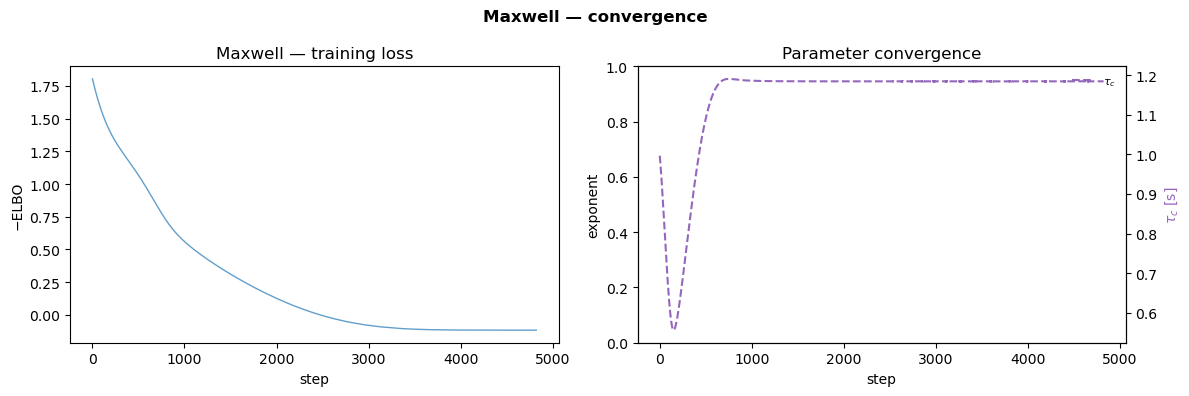

FractionalMaxwellGel: ran 7934/20000 epochs -- early-stopped (loss plateaued)


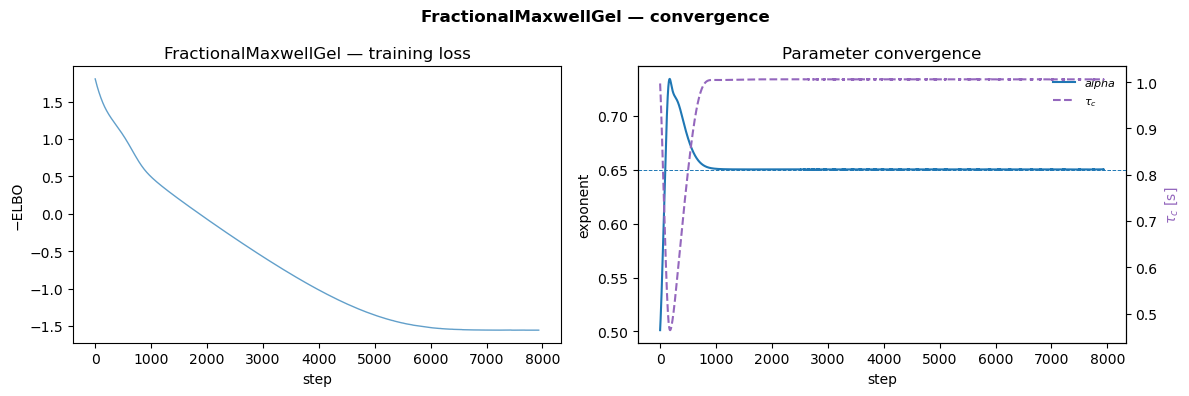

FractionalMaxwellLiquid: ran 5860/20000 epochs -- early-stopped (loss plateaued)


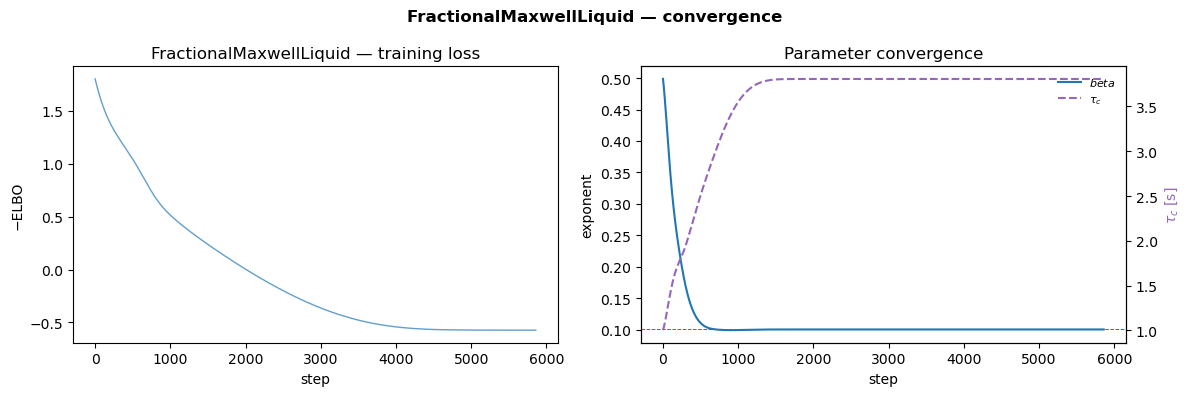

FractionalMaxwell: ran 8060/20000 epochs -- early-stopped (loss plateaued)


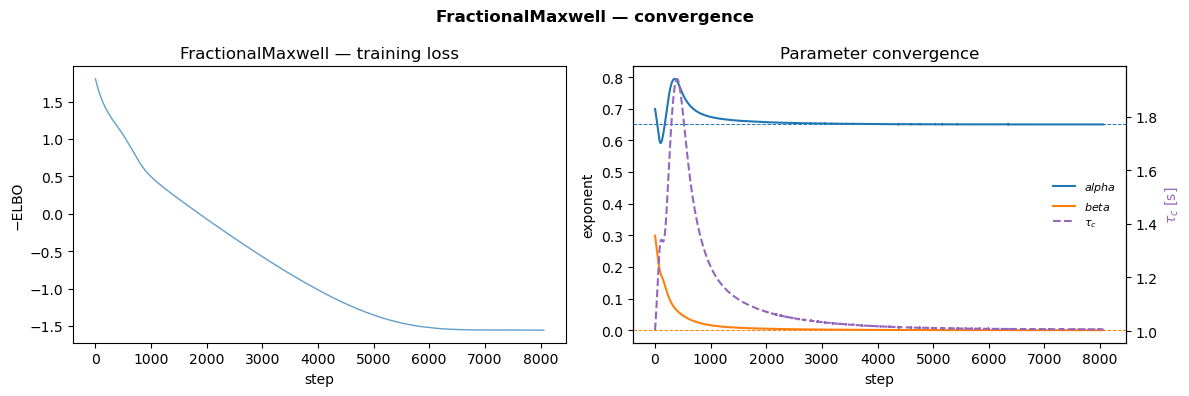

In [37]:
n_budget = FITKW_CANDIDATES["n_epochs"]

for name, mc in curves.items():
    hist = mc.model_.history_
    n_ran = len(hist.get("loss", []))
    stopped_early = n_ran < n_budget
    tag = "early-stopped (loss plateaued)" if stopped_early else \
          "HIT THE EPOCH BUDGET -- inspect the curve below before trusting this fit"
    print(f"{name}: ran {n_ran}/{n_budget} epochs -- {tag}")
    mc.model_.plot_convergence()
    plt.show()


## 5b) Effective sample size correction (BIC_eff)

`compare_master_curve_models` scores each candidate with
`BIC = 2*NLL + k*ln(N)`, where `N = metrics_["n_data"]` is the RAW number
of time samples pooled across every chirp. But adjacent residuals in a
chirp sampled far above the material's own relaxation bandwidth are
nearly the same number repeated, not independent draws, so `N`
overstates how much *independent* evidence backs the fit -- the same
issue as in `035_real_data_model_selection.ipynb`.

The standard fix (Sokal 1989 -- the same estimator emcee/ArviZ use for
MCMC chains) is to replace `N` by an effective sample size
`N_eff = N / tau_int`, where `tau_int` is the residuals' own integrated
autocorrelation time (`rheogp.utils.effective_sample_size_segments`,
computed **per record and summed**, since autocorrelation only means
something *within* one chirp).

In [38]:
from rheogp.utils import effective_sample_size_segments

print(f"{'Model':<26} {'N':>10} {'N_eff':>10} {'mean tau_int':>13} "
      f"{'elbo_per_point':>15} {'k':>4}")
neff_report = {}
for name, mc in sorted(curves.items(), key=lambda kv: kv[1].metrics_["bic"]):
    mj_c = mc.model_
    residual_segments = [mj_c.stress_[lo:hi] - mj_c.pred_[lo:hi] for lo, hi in mj_c._bounds]
    n_eff, n_raw, per_seg = effective_sample_size_segments(residual_segments)
    m = mc.metrics_
    k = m["n_params"]["k_total"]
    mean_tau = float(np.mean([tau for _, tau, _ in per_seg]))
    neff_report[name] = dict(n_eff=n_eff, n_raw=n_raw, mean_tau=mean_tau,
                              per_record=per_seg)
    print(f"{name:<26} {n_raw:>10d} {n_eff:>10.1f} {mean_tau:>13.1f} "
          f"{m['elbo_per_point']:>15.6g} {k:>4d}")

Model                               N      N_eff  mean tau_int  elbo_per_point    k
FractionalMaxwellGel            51624    50352.8           1.0        -1.55693   15
FractionalMaxwell               51624    50237.0           1.0        -1.55696   16
FractionalMaxwellLiquid         51624      387.2         166.8       -0.572911   15
Maxwell                         51624      407.5         192.0       -0.117193   14


In [39]:
# Deliberately not baked into a library function -- how to fold N_eff
# back into an information criterion is a modeling choice with real
# ambiguity: does it only correct the k*ln(N) penalty (leaving the
# likelihood term computed under the raw N untouched), or does it also
# rescale the likelihood term itself (elbo_per_point * N_eff, since
# elbo_per_point is only really representative of N_eff independent
# samples)? Both conventions are printed below; `bic_raw` matches
# `mc.metrics_["bic"]` exactly, as a sanity check.
print(f"{'Model':<26} {'BIC (raw N)':>14} {'BIC_eff (penalty-only)':>24} {'BIC_eff (full rescale)':>24}")
for name, mc in sorted(curves.items(), key=lambda kv: kv[1].metrics_["bic"]):
    m = mc.metrics_
    elbo_pp = m["elbo_per_point"]          # best/final per-point -ELBO from training
    N       = m["n_data"]                  # raw sample count
    k       = m["n_params"]["k_total"]
    N_eff   = neff_report[name]["n_eff"]   # from the effective_sample_size_segments cell above

    bic_raw         = 2.0 * N * elbo_pp + k * np.log(N)                # == metrics_["bic"]
    bic_eff_penalty = 2.0 * N * elbo_pp + k * np.log(N_eff)            # only the penalty corrected
    bic_eff_full    = 2.0 * N_eff * elbo_pp + k * np.log(N_eff)        # likelihood term rescaled too

    print(f"{name:<26} {bic_raw:>14.1f} {bic_eff_penalty:>24.1f} {bic_eff_full:>24.1f}")

Model                         BIC (raw N)   BIC_eff (penalty-only)   BIC_eff (full rescale)
FractionalMaxwellGel            -160586.6                -160587.0                -156628.8
FractionalMaxwell               -160578.9                -160579.3                -156260.3
FractionalMaxwellLiquid          -58989.1                 -59062.5                   -354.3
Maxwell                          -11948.1                 -12015.8                    -11.4


## 6) Composite figure

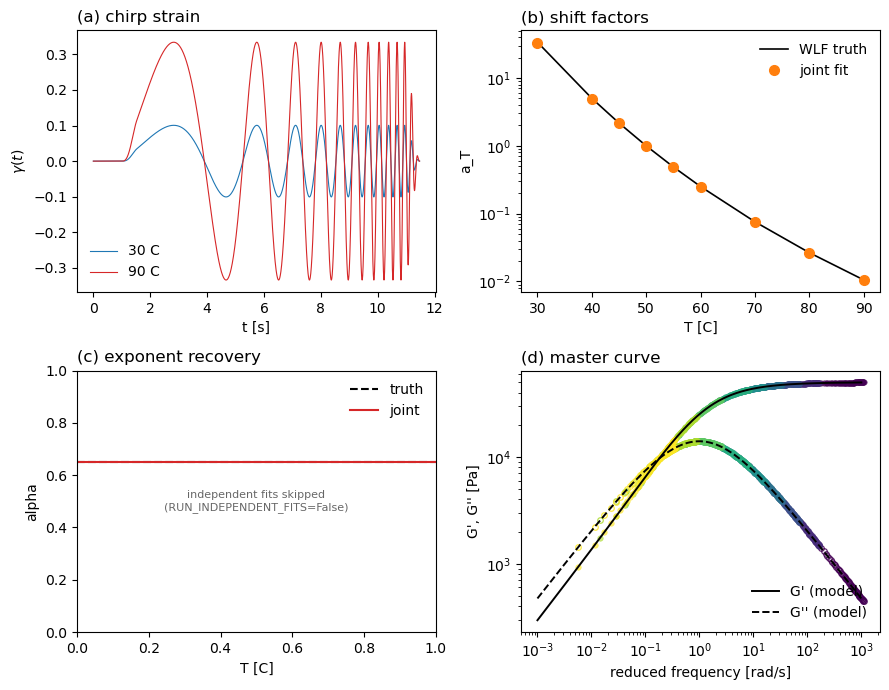

In [40]:
cmap = plt.get_cmap("viridis")
fig, axs = plt.subplots(2, 2, figsize=(9, 7))
axA, axB, axC, axD = axs.ravel()

t0, g0_, _ = records[0]; t1, g1_, _ = records[-1]
axA.plot(t0, g0_, lw=0.8, color="tab:blue", label=f"{TEMPS[0]:g} C")
axA.plot(t1, g1_, lw=0.8, color="tab:red", label=f"{TEMPS[-1]:g} C")
axA.set_xlabel("t [s]"); axA.set_ylabel(r"$\gamma(t)$"); axA.legend(frameon=False)
axA.set_title("(a) chirp strain", loc="left")

axB.semilogy(TEMPS, aT_true, "k-", lw=1.2, label="WLF truth")
axB.semilogy(TEMPS, aT_fit, "o", ms=7, color="tab:orange", label="joint fit")
axB.set_xlabel("T [C]"); axB.set_ylabel("a_T"); axB.legend(frameon=False)
axB.set_title("(b) shift factors", loc="left")

pj = mj.gp_model_.phys.named_phys_params()
if indep:
    axC.plot(TEMPS, [indep[T].gp_model_.phys.named_phys_params()["alpha"] for T in TEMPS],
              "o-", ms=6, color="tab:blue", label="alpha indep.")
else:
    axC.text(0.5, 0.5, "independent fits skipped\n(RUN_INDEPENDENT_FITS=False)",
              transform=axC.transAxes, ha="center", va="center", fontsize=8, color="0.4")
axC.axhline(truth["alpha"], color="k", ls="--", label="truth")
axC.axhline(pj["alpha"], color="tab:red", label="joint")
axC.set_xlabel("T [C]"); axC.set_ylabel("alpha"); axC.legend(frameon=False)
axC.set_title("(c) exponent recovery", loc="left")

# G' (storage) is plotted with SOLID markers, G'' (loss) with HOLLOW
# (open) markers, both bigger than the default "." so individual data
# points stay distinguishable from the model lines drawn under them.
res = mj.results(); bounds = mj._bounds; aT_arr = np.asarray(aT_fit, float)
pf = mj.prefactors_
for i, ((t, strain, _), (lo, hi)) in enumerate(zip(records, bounds)):
    omega, G = fft_transfer(t, strain, res.prediction[lo:hi], min_snr_db=30.0)
    col = cmap(i / (len(TEMPS) - 1))
    axD.loglog(omega * aT_arr[i], np.real(G), "o", ms=4, mfc=col, mec=col,
               mew=0.4, alpha=0.65, linestyle="none")
    axD.loglog(omega * aT_arr[i], np.imag(G), "o", ms=4, mfc="none", mec=col,
               mew=0.9, alpha=0.85, linestyle="none")
omega_line = np.logspace(-3, 3, 800)
G_line = gstar_fmm(omega_line, pf["Gc"]["scalar_mean"], pj["alpha"], pj["beta"], pj["tau_c"])
axD.loglog(omega_line, np.real(G_line), "k-", lw=1.4, label="G' (model)")
axD.loglog(omega_line, np.imag(G_line), "k--", lw=1.4, label="G'' (model)")
axD.set_xlabel("reduced frequency [rad/s]"); axD.set_ylabel("G', G'' [Pa]")
axD.legend(frameon=False, loc="lower right"); axD.set_title("(d) master curve", loc="left")

fig.tight_layout()
fig.savefig("fig_tts_fmm.png", dpi=300, bbox_inches="tight")
fig.savefig("fig_tts_fmm.pdf", bbox_inches="tight")
plt.show()

## 7) Export LaTeX macros + model-comparison table for `main.tex`

In [41]:
metrics = mj.metrics_
aT_errs = [100 * (af - at) / at for af, at in zip(aT_fit, aT_true)]

_FMM_DISPLAY = {"FractionalMaxwell": "FMM", "FractionalMaxwellGel": "FMG",
                "FractionalMaxwellLiquid": "FML", "Maxwell": "Maxwell"}
_winner_ranked = sorted(curves.items(), key=lambda kv: kv[1].metrics_["bic"])
_winner_name, _winner_mc = _winner_ranked[0]
_runner_name, _runner_mc = _winner_ranked[1]

macros = dict(
    fmmSynBICWinner=_FMM_DISPLAY.get(_winner_name, _winner_name),
    fmmSynBICWinnerFull=_winner_name,
    fmmSynBICWinnerVal=f"{_winner_mc.metrics_['bic']:.1f}",
    fmmSynBICRunnerUp=_FMM_DISPLAY.get(_runner_name, _runner_name),
    fmmSynDeltaBICRunnerUp=f"{_runner_mc.metrics_['bic'] - _winner_mc.metrics_['bic']:.1f}",
    fmmSynNTemps=len(TEMPS),
    fmmSynTempMin=f"{min(TEMPS):g}", fmmSynTempMax=f"{max(TEMPS):g}",
    fmmSynTempRef=f"{truth['T_ref']:g}",
    fmmSynAlphaTruth=f"{truth['alpha']:.3f}", fmmSynBetaTruth=f"{truth['beta']:.3f}",
    fmmSynGcTruth=f"{truth['Gc']:.3g}", fmmSynTauRefTruth=f"{truth['tau_ref']:.3f}",
    fmmSynCOneTruth=f"{truth['C1']:.2f}", fmmSynCTwoTruth=f"{truth['C2']:.1f}",
    fmmSynAlphaFit=f"{pj['alpha']:.4f}",
    fmmSynAlphaErrPct=pct(100 * (pj["alpha"] - truth["alpha"]) / truth["alpha"]),
    fmmSynBetaFit=f"{pj['beta']:.4f}",
    fmmSynTauCFit=f"{pj['tau_c']:.4f}",
    fmmSynGcFit=f"{pf['Gc']['scalar_mean']:.4g}",
    fmmSynGcErrPct=pct(100 * (pf["Gc"]["scalar_mean"] - truth["Gc"]) / truth["Gc"]),
    fmmSynGcCIlo=f"{pf['Gc']['scalar_lower']:.4g}", fmmSynGcCIhi=f"{pf['Gc']['scalar_upper']:.4g}",
    fmmSynRMSE=f"{metrics['rmse']:.4g}", fmmSynRsq=f"{metrics['r2']:.6f}",
    fmmSynBIC=f"{metrics['bic']:.1f}", fmmSynKTotal=metrics["n_params"]["k_total"],
    fmmSynNShift=metrics["n_params"]["n_shift"], fmmSynNData=metrics["n_data"],
    fmmSynATErrMin=pct(min(aT_errs)), fmmSynATErrMax=pct(max(aT_errs)),
    fmmSynWLFCOneFit=f"{C1f:.3f}", fmmSynWLFCOneSD=f"{sd[0]:.3f}",
    fmmSynWLFCTwoFit=f"{C2f:.2f}", fmmSynWLFCTwoSD=f"{sd[1]:.2f}",
    fmmSynBICSelected="true" if FMM_SELECTED else "false",
)
write_macros("results_fmm.tex", macros)

table_src = model_comparison_latex_table(
    curves, criterion="bic",
    caption=(f"Model comparison for the synthetic Fractional Maxwell (FMM) "
             f"dataset, {len(TEMPS)} chirps jointly fit ($N=$\\fmmSynNData"
             "). Lower $\\Delta$BIC is better; $\\Delta=0$ marks the "
             "selected model. Each candidate shares the identical set of "
             "chirps and the identical horizontal-shift parameterisation, "
             "so only the constitutive term differs between rows."),
    label="tab:fmm_synthetic_ic",
    display_names={"FractionalMaxwell": "FMM (generating model)",
                    "FractionalMaxwellGel": "FMG", "FractionalMaxwellLiquid": "FML",
                    "Maxwell": "Maxwell"})
write_table("table_fmm.tex", table_src)
print(table_src)

wrote 36 macros -> results_fmm.tex
wrote table -> table_fmm.tex
\begin{table*}[t]
  \centering
  \caption{Model comparison for the synthetic Fractional Maxwell (FMM) dataset, 9 chirps jointly fit ($N=$\fmmSynNData). Lower $\Delta$BIC is better; $\Delta=0$ marks the selected model. Each candidate shares the identical set of chirps and the identical horizontal-shift parameterisation, so only the constitutive term differs between rows.}
  \label{tab:fmm_synthetic_ic}
  \small
  \setlength{\tabcolsep}{4pt}
  \renewcommand{\arraystretch}{1.2}
  \begin{tabular}{lccccccccccc}
    \hline
    Model & $2\mathcal{U}$ & $2k$ & $k\ln N$ & AIC & BIC & $\Delta$BIC & RMSE [Pa] & $R^2$ & $\alpha$ & $\beta$ & $\tau_{c}$ \\
    \hline
    FMG & -160749 & 30 & 162.78 & -160719 & -160587 & 0 & 165.1 & 0.9975 & 0.65 & -- & 1.01 \\
    FMM (generating model) & -160753 & 32 & 173.63 & -160721 & -160579 & 7.76 & 165.1 & 0.9975 & 0.65 & 4.19e-05 & 1.01 \\
    FML & -59151.9 & 30 & 162.78 & -59121.9 & -58989.1 &

## 8) Export the full dataset for replotting elsewhere (scienceplots, etc.)

In [42]:
from paper_utils import export_master_curve

export_master_curve(
    "fmm_export", mj, records, TEMPS, I_REF,
    truth=truth,
    wlf=dict(C1=C1f, C2=C2f, C1_std=sd[0], C2_std=sd[1]),
    aT_true=aT_true,
)
# On another machine (no rheogp/torch needed):
#   from paper_utils import load_master_curve_export
#   d = load_master_curve_export("fmm_export")
#   d.meta                             -> model name, physical params (alpha,
#                                          beta, tau_c), prefactor CIs, metrics,
#                                          ground truth, WLF fit
#   d.record(i)["t"/"gamma"/"sigma"]   -> raw chirp i
#   d.record(i)["pred"/"pred_std"]     -> fitted stress +/- posterior std
#   d.record(i)["fft_omega"/"fft_Gp"/"fft_Gdp"]
#                                       -> chirp i's own (unshifted) FFT of the
#                                          RAW measured signal
#   d.record(i)["fft_omega_reduced"]   -> same, shifted to the reference temp.
#   d.record(i)["fftpred_omega_reduced"/"fftpred_Gp"/"fftpred_Gdp"]
#                                       -> FFT of the model's own (denoised)
#                                          prediction, reduced -- what Fig. 2(d)
#                                          in the paper actually scatter-plots
#   d.record(i)["sens_Gc_mean"/"_lower"/"_upper"]
#                                       -> time-resolved prefactor sensitivity
#                                          (the "quasi-property" panel)
#   d.arrays["shift_factors"]          -> fitted a_T, in TEMPS order
#   d.arrays["shift_factors_truth"]    -> WLF ground-truth a_T, same order
#   d.arrays["hist_loss"], d.arrays["hist_param_alpha"], ...
#                                       -> training traces (loss/params vs. epoch)
#   d.model_curve                      -> (omega, Gp, Gdp, Gp_ci, Gdp_ci), the
#                                          analytic master curve + credible band

exported 9 records -> fmm_export.npz + fmm_export.json


('fmm_export.npz', 'fmm_export.json')

## 9) Robustness to measurement noise

Everything above uses the default `noise_frac = 0.03` chirp (3% i.i.d.
Gaussian noise on the stress signal, `CHIRP["noise_frac"]`). Here we
regenerate the dataset at several noise levels, refit the joint TRUE
model at each, and track (a) how the shared shape/prefactor parameters
degrade with noise and (b) whether the AIC/BIC candidate-family
comparison from Sec. 5 still recovers the correct model once the data
are noisy -- rerun in full at the highest noise level tested.

  [FractionalMaxwell] step     0 | -ELBO 1.8035 | alpha=0.699  beta=0.299  tau_c=1.003 | wait 0
  [FractionalMaxwell] step   200 | -ELBO 1.3884 | alpha=0.681  beta=0.128  tau_c=1.423 | wait 0
  [FractionalMaxwell] step   400 | -ELBO 1.1609 | alpha=0.786  beta=0.061  tau_c=1.939 | wait 0
  [FractionalMaxwell] step   600 | -ELBO 0.9309 | alpha=0.716  beta=0.036  tau_c=1.615 | wait 0
  [FractionalMaxwell] step   800 | -ELBO 0.6753 | alpha=0.686  beta=0.023  tau_c=1.364 | wait 0
  [FractionalMaxwell] step  1000 | -ELBO 0.4930 | alpha=0.674  beta=0.016  tau_c=1.238 | wait 0
  [FractionalMaxwell] step  1200 | -ELBO 0.3631 | alpha=0.667  beta=0.011  tau_c=1.171 | wait 0
  [FractionalMaxwell] step  1400 | -ELBO 0.2471 | alpha=0.664  beta=0.009  tau_c=1.131 | wait 0
  [FractionalMaxwell] step  1600 | -ELBO 0.1363 | alpha=0.661  beta=0.007  tau_c=1.105 | wait 0
  [FractionalMaxwell] step  1800 | -ELBO 0.0277 | alpha=0.659  beta=0.006  tau_c=1.085 | wait 0
  [FractionalMaxwell] step  2000 | -ELBO

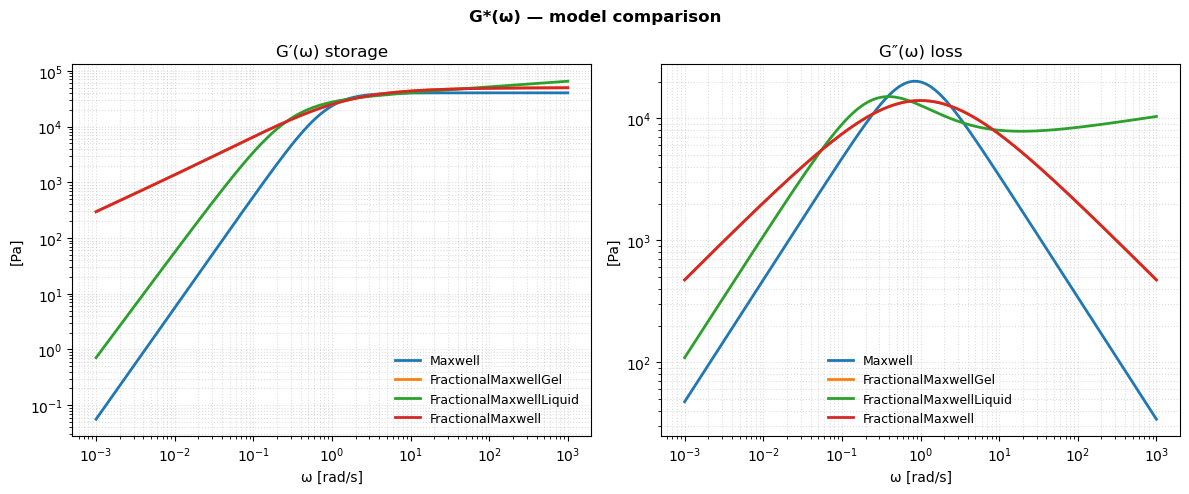

  [noise=0.03] Maxwell: ran 5040/20000 epochs -- early-stopped


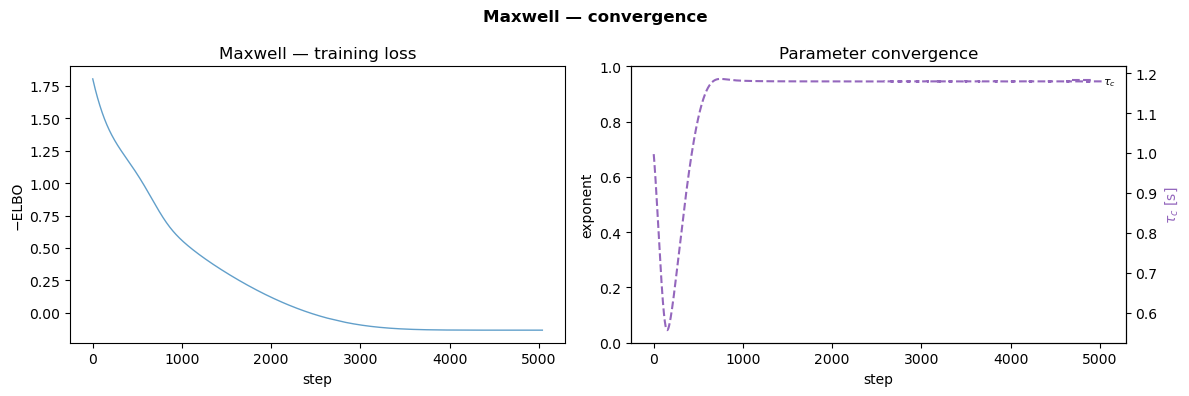

  [noise=0.03] FractionalMaxwellGel: ran 9297/20000 epochs -- early-stopped


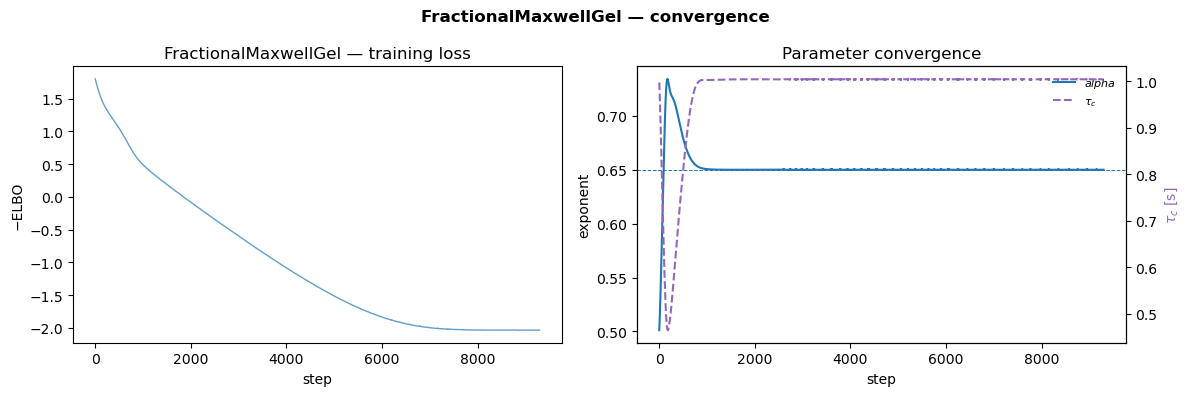

  [noise=0.03] FractionalMaxwellLiquid: ran 5972/20000 epochs -- early-stopped


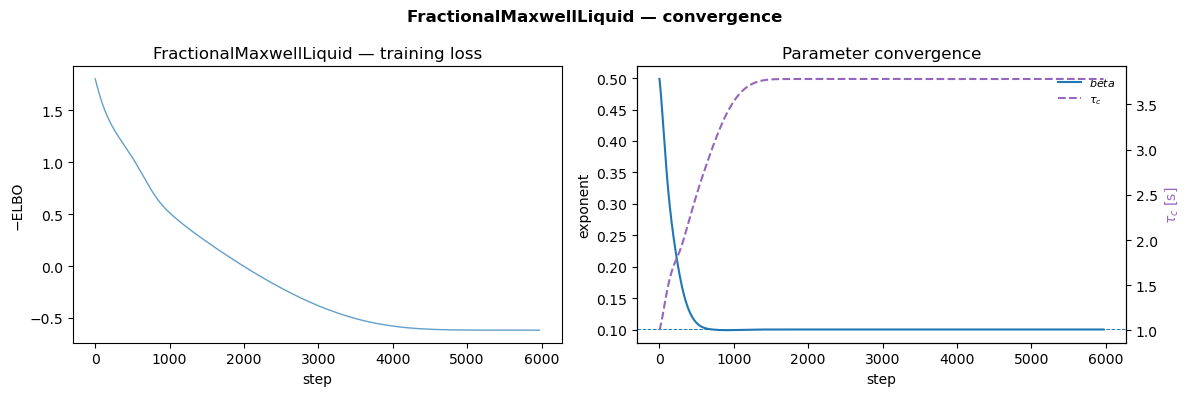

  [noise=0.03] FractionalMaxwell: ran 9355/20000 epochs -- early-stopped


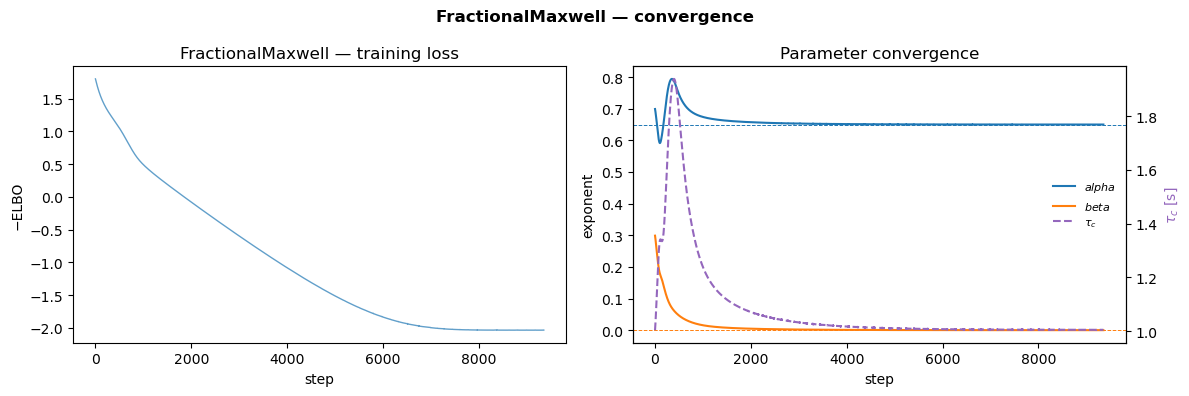

exported 9 records -> fmg_export_noise003.npz + fmg_export_noise003.json

  -- N_eff / BIC_eff at noise_frac=0.03 --
  Model                             N    N_eff     BIC(raw)   BIC_eff(pen)  BIC_eff(full)
  FractionalMaxwellGel          51624  49977.3    -209958.6      -209959.1      -203256.7
  FractionalMaxwell             51624  49604.6    -209951.6      -209952.2      -201732.5
  FractionalMaxwellLiquid       51624    338.5     -63604.4       -63679.8         -330.7
  Maxwell                       51624    388.3     -13697.7       -13766.2          -20.7
noise_frac=0.03  alpha_err=-0.01%  Gc_err=-0.06%  RMSE=98.89  R2=0.99910
  noise sd: injected 98.97 Pa  ->  GP inferred 104.4 Pa  (ratio 1.055)
  AIC          -> 'FractionalMaxwell' (correct: False)
  BIC (raw N)  -> 'FractionalMaxwellGel' (correct: True)
  BIC_eff(pen) -> 'FractionalMaxwellGel' (correct: True, changed vs. raw BIC: False)
  BIC_eff(full)-> 'FractionalMaxwellGel' (correct: True, changed vs. raw BIC: False)
  [Frac

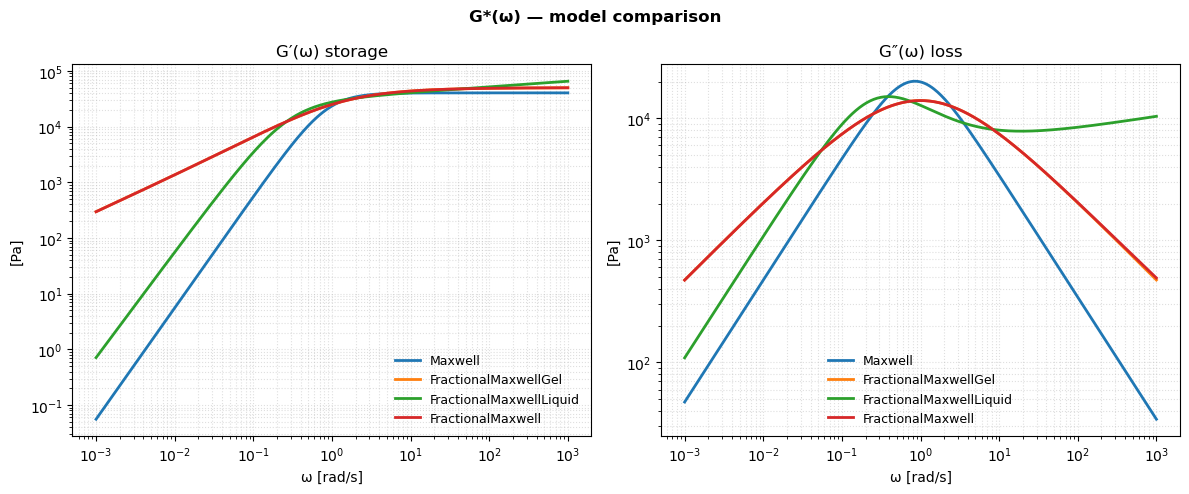

  [noise=0.08] Maxwell: ran 4761/20000 epochs -- early-stopped


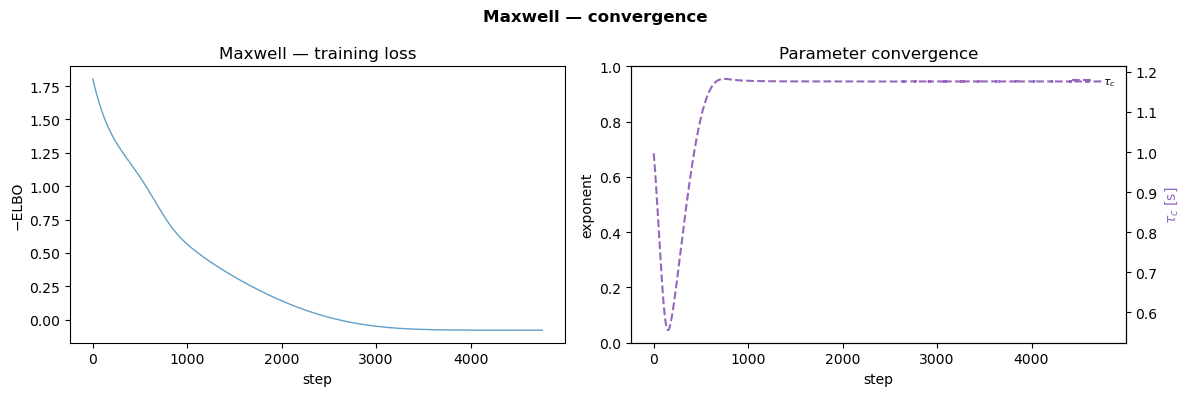

  [noise=0.08] FractionalMaxwellGel: ran 6970/20000 epochs -- early-stopped


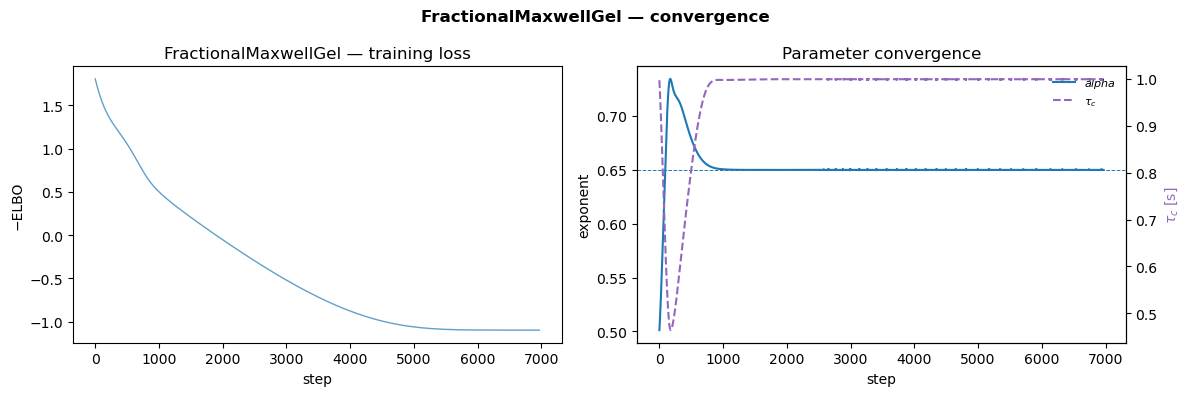

  [noise=0.08] FractionalMaxwellLiquid: ran 5783/20000 epochs -- early-stopped


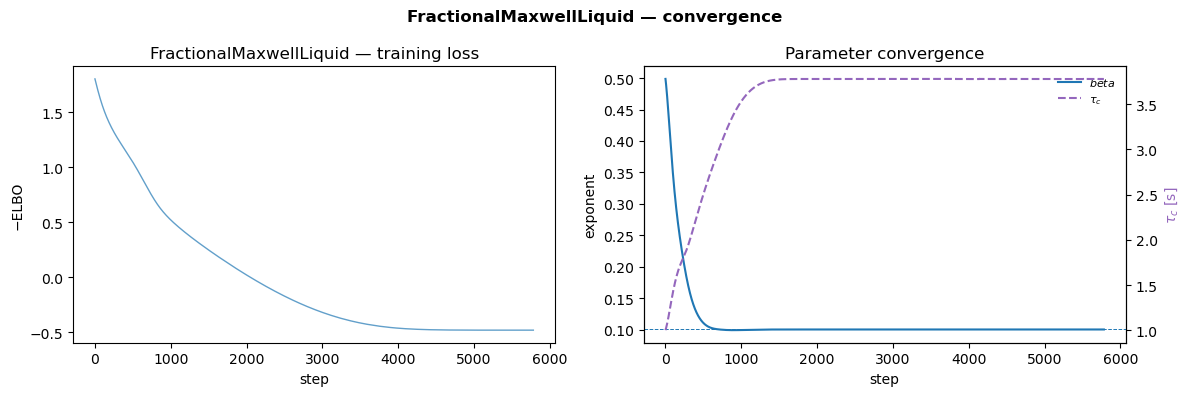

  [noise=0.08] FractionalMaxwell: ran 7114/20000 epochs -- early-stopped


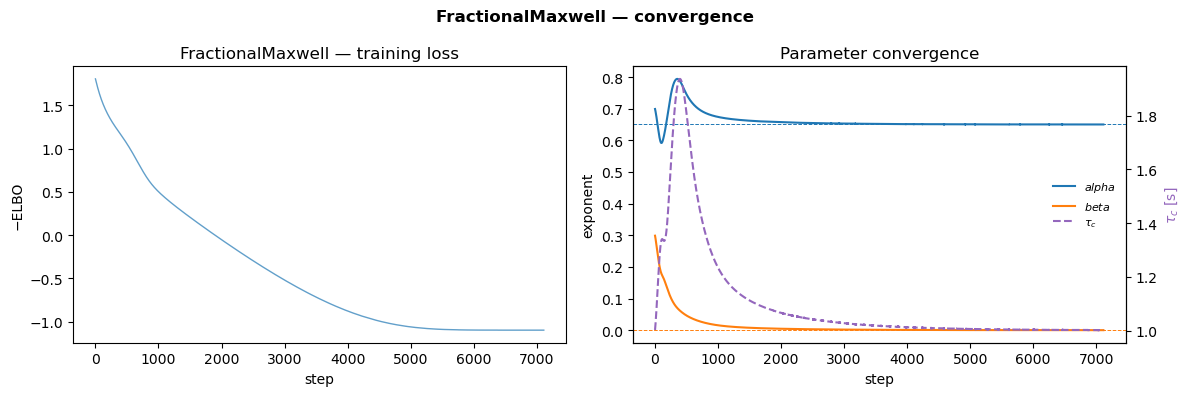

exported 9 records -> fmg_export_noise008.npz + fmg_export_noise008.json

  -- N_eff / BIC_eff at noise_frac=0.08 --
  Model                             N    N_eff     BIC(raw)   BIC_eff(pen)  BIC_eff(full)
  FractionalMaxwellGel          51624  51290.4    -113081.5      -113081.6      -112349.8
  FractionalMaxwell             51624  51289.5    -113074.9      -113075.0      -112341.2
  FractionalMaxwellLiquid       51624    498.0     -49387.1       -49456.8         -384.9
  Maxwell                       51624    459.8      -7895.4        -7961.5           14.2
noise_frac=0.08  alpha_err=+0.01%  Gc_err=-0.12%  RMSE=265.3  R2=0.99358
  noise sd: injected 263.9 Pa  ->  GP inferred 267.6 Pa  (ratio 1.014)
  AIC          -> 'FractionalMaxwell' (correct: False)
  BIC (raw N)  -> 'FractionalMaxwellGel' (correct: True)
  BIC_eff(pen) -> 'FractionalMaxwellGel' (correct: True, changed vs. raw BIC: False)
  BIC_eff(full)-> 'FractionalMaxwellGel' (correct: True, changed vs. raw BIC: False)
  [Frac

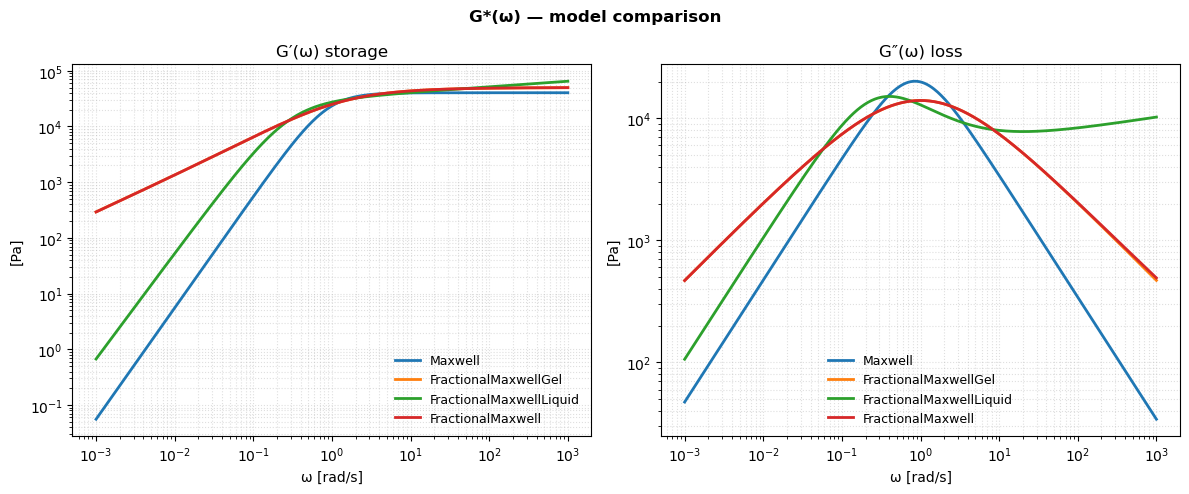

  [noise=0.15] Maxwell: ran 4420/20000 epochs -- early-stopped


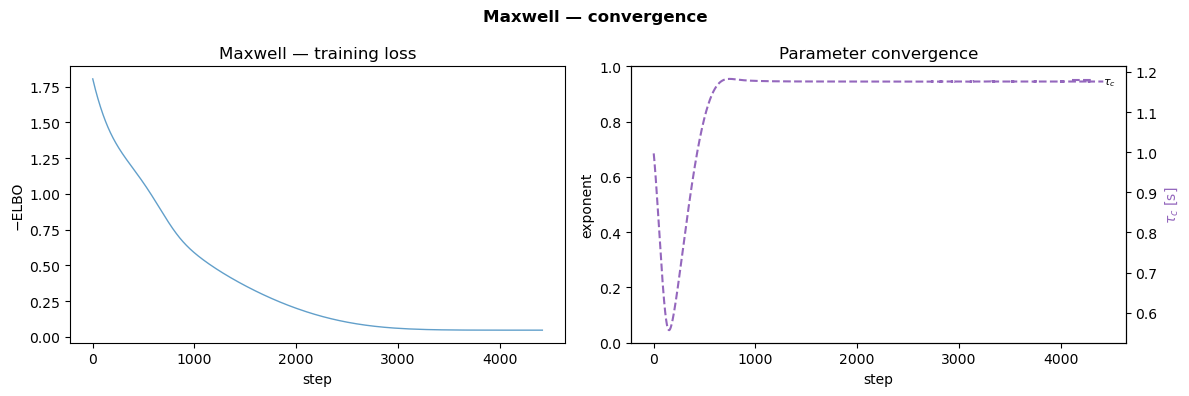

  [noise=0.15] FractionalMaxwellGel: ran 5751/20000 epochs -- early-stopped


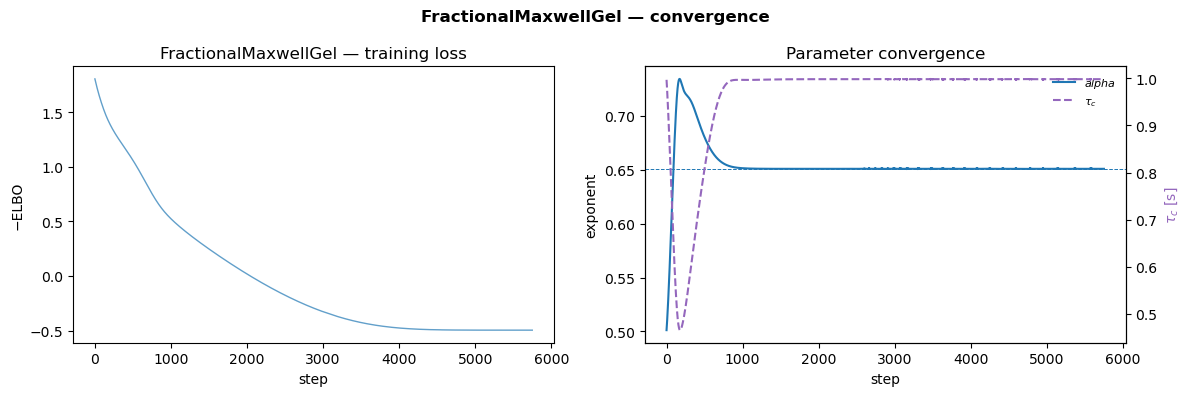

  [noise=0.15] FractionalMaxwellLiquid: ran 5091/20000 epochs -- early-stopped


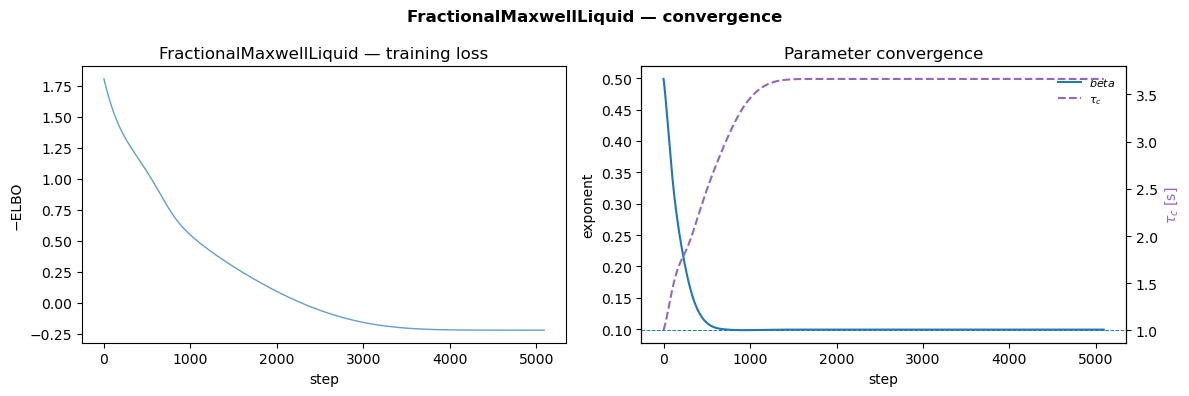

  [noise=0.15] FractionalMaxwell: ran 5961/20000 epochs -- early-stopped


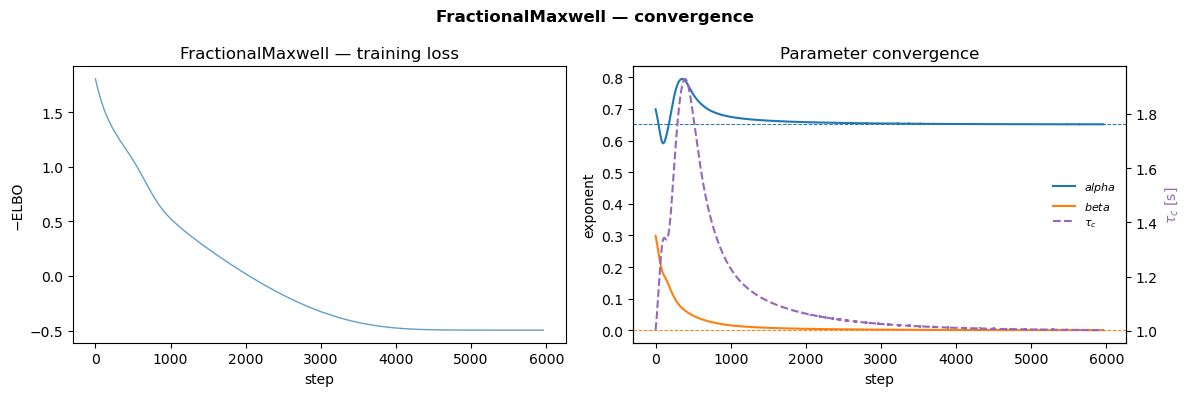

exported 9 records -> fmg_export_noise015.npz + fmg_export_noise015.json

  -- N_eff / BIC_eff at noise_frac=0.15 --
  Model                             N    N_eff     BIC(raw)   BIC_eff(pen)  BIC_eff(full)
  FractionalMaxwellGel          51624  51414.8     -51058.5       -51058.6       -50851.1
  FractionalMaxwell             51624  51413.0     -51050.4       -51050.5       -50841.1
  FractionalMaxwellLiquid       51624    969.9     -22851.8       -22911.4         -329.2
  Maxwell                       51624    644.7       5013.3         4952.0          151.3
noise_frac=0.15  alpha_err=+0.21%  Gc_err=-0.19%  RMSE=490.1  R2=0.97841
  noise sd: injected 494.8 Pa  ->  GP inferred 491.6 Pa  (ratio 0.993)
  AIC          -> 'FractionalMaxwell' (correct: False)
  BIC (raw N)  -> 'FractionalMaxwellGel' (correct: True)
  BIC_eff(pen) -> 'FractionalMaxwellGel' (correct: True, changed vs. raw BIC: False)
  BIC_eff(full)-> 'FractionalMaxwellGel' (correct: True, changed vs. raw BIC: False)
  [Frac

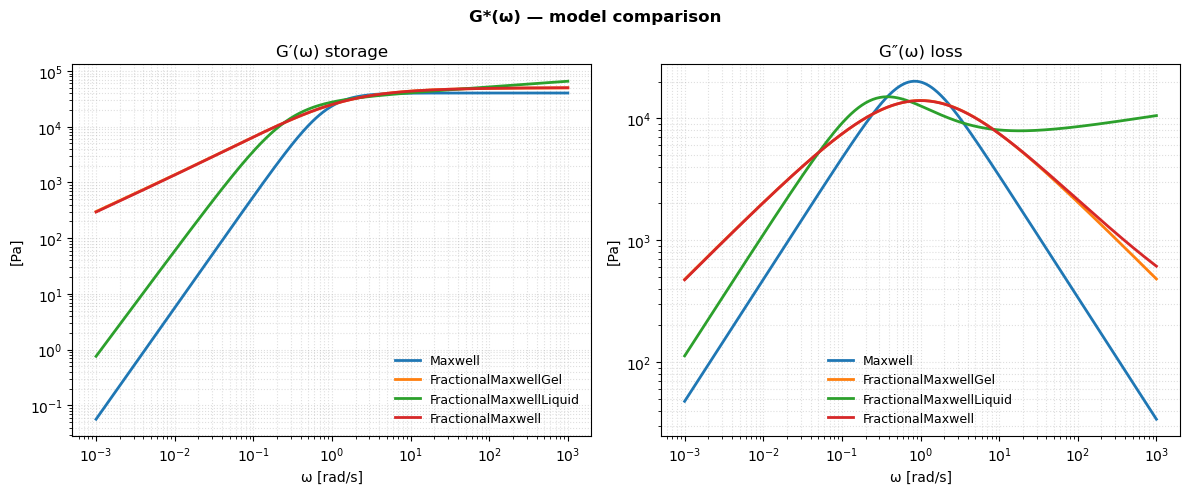

  [noise=0.25] Maxwell: ran 3972/20000 epochs -- early-stopped


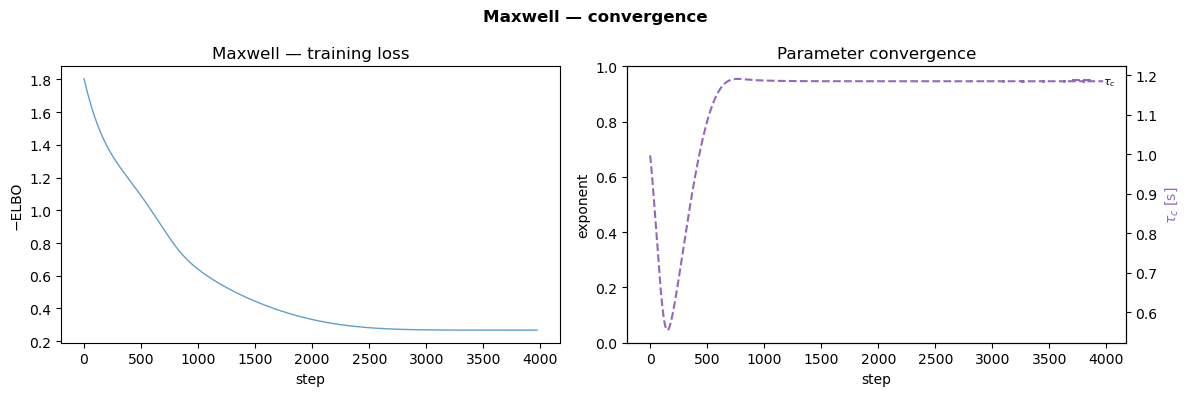

  [noise=0.25] FractionalMaxwellGel: ran 4707/20000 epochs -- early-stopped


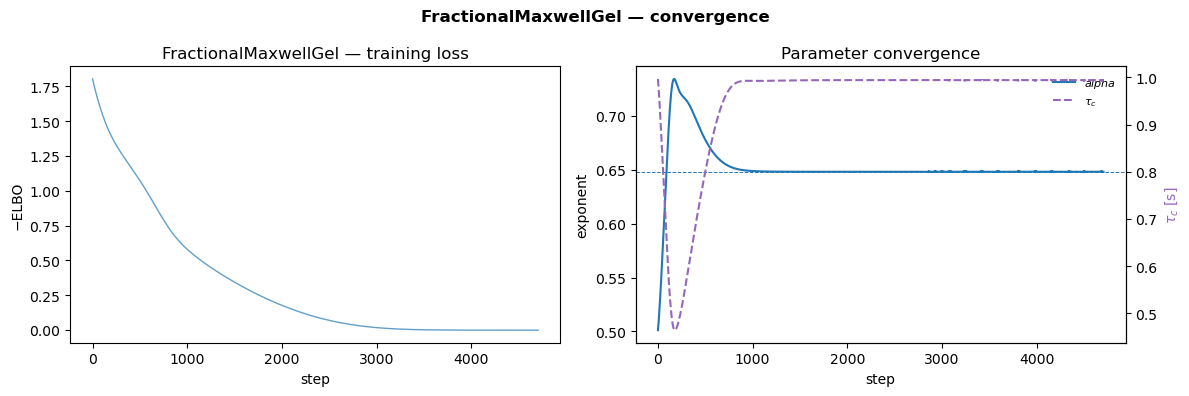

  [noise=0.25] FractionalMaxwellLiquid: ran 4318/20000 epochs -- early-stopped


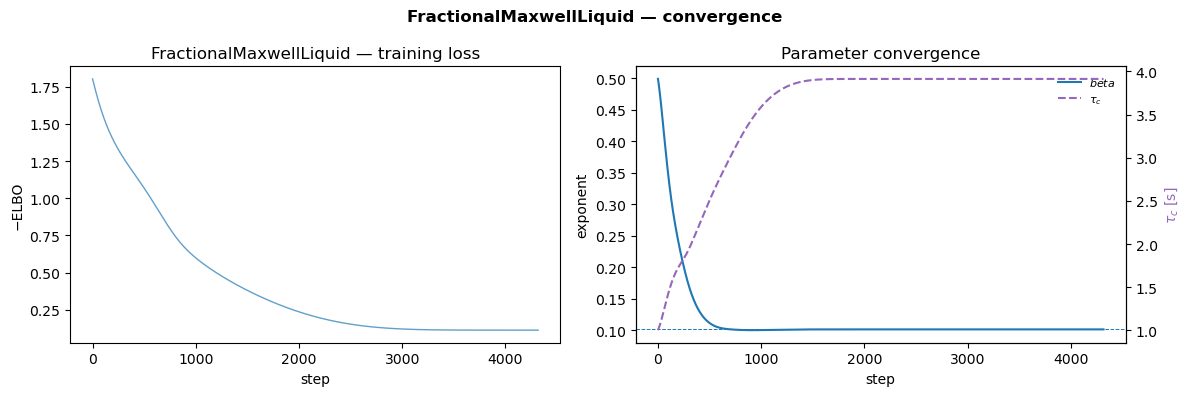

  [noise=0.25] FractionalMaxwell: ran 4669/20000 epochs -- early-stopped


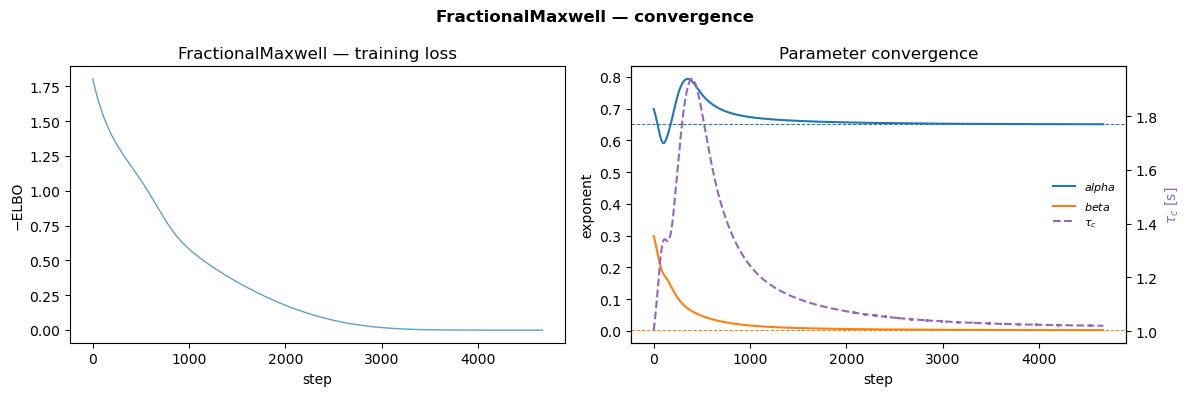

exported 9 records -> fmg_export_noise025.npz + fmg_export_noise025.json

  -- N_eff / BIC_eff at noise_frac=0.25 --
  Model                             N    N_eff     BIC(raw)   BIC_eff(pen)  BIC_eff(full)
  FractionalMaxwellGel          51624  50706.6        -34.3          -34.6          -31.1
  FractionalMaxwell             51624  50720.4        -23.9          -24.2          -20.7
  FractionalMaxwellLiquid       51624   2702.1      11743.7        11699.5          724.7
  Maxwell                       51624   1088.4      27780.0        27725.9          680.4
noise_frac=0.25  alpha_err=+0.16%  Gc_err=-0.65%  RMSE=819.8  R2=0.94181
  noise sd: injected 824.7 Pa  ->  GP inferred 821.4 Pa  (ratio 0.996)
  AIC          -> 'FractionalMaxwellGel' (correct: True)
  BIC (raw N)  -> 'FractionalMaxwellGel' (correct: True)
  BIC_eff(pen) -> 'FractionalMaxwellGel' (correct: True, changed vs. raw BIC: False)
  BIC_eff(full)-> 'FractionalMaxwellGel' (correct: True, changed vs. raw BIC: False)

At n

In [43]:
from scipy.optimize import curve_fit

from paper_utils import export_master_curve, fmt
from rheogp.utils import effective_sample_size_segments

NOISE_LEVELS = [0.03, 0.08, 0.15, 0.25]   # fraction of stress std (Gaussian)
TRUE_MODEL = "FractionalMaxwellGel"          # expected correct model (normalized below)

# A full `export_master_curve()` bundle is written for ONE candidate at
# EVERY noise level, so `fmm_plotting.ipynb` can draw its master-curve
# figure per noise level instead of only at the default one. FMG is the
# beta -> 0 limit the data were actually generated from, so it is the
# description those per-noise figures should be drawn with. Set to None
# to skip the extra exports.
EXPORT_MODEL_PER_NOISE = "FractionalMaxwellGel"
EXPORT_TAG_PER_NOISE = "fmg_export_noise{pct:03d}"
# The master-curve figure defaults to MASTER_CURVE_SOURCE="posterior",
# which reads the posterior-predictive FFT ensemble -- so that ensemble
# has to be IN the bundle. It costs about as much as the prefactor
# extraction the fit has already done, once per noise level.
EXPORT_POSTERIOR_FFT_PER_NOISE = True

# The four selection rules compared at every noise level: the two the
# library computes on the RAW sample count, and the two N_eff-corrected
# BIC conventions of Sec. 5b. Kept as one list so the winner under each
# is read off the same per-candidate record, with no criterion getting a
# refit of its own (`criterion=` only picks which candidate
# `compare_master_curve_models` calls "best", not what gets fitted).
CRITERIA = ["aic", "bic_raw", "bic_eff_pen", "bic_eff_full"]


def _norm_model_name(s):
    return s.lower().replace(" ", "")


def _prefactor_dict(m):
    return {k: dict(mean=float(v["scalar_mean"]),
                    lower=float(v["scalar_lower"]),
                    upper=float(v["scalar_upper"]))
            for k, v in m.prefactors_.items()}


def _wlf_from_aT(aT, temps, T_ref, p0=(8.0, 130.0)):
    """WLF constants regressed from one fit's own shift factors -- the
    same regression as Sec. 4, rerun per noise level so C1/C2 can be
    traced against noise alongside the shape parameters."""
    Tv = np.asarray(temps, float)
    f = lambda TT, C1, C2: -C1 * (TT - T_ref) / (C2 + TT - T_ref)
    (C1, C2), cov = curve_fit(f, Tv, np.log10(np.asarray(aT, float)),
                              p0=list(p0), maxfev=40000)
    s = np.sqrt(np.diag(cov))
    return dict(C1=float(C1), C2=float(C2),
                C1_std=float(s[0]), C2_std=float(s[1]))


# Per-point residuals and predictive standard deviations, kept for
# EVERY candidate at every noise level, so that
# `fmm_plotting.ipynb` can build the weighted-RSS forms of BIC
# (weights = the data point, or the GP's own predictive std) without
# refitting anything. The scalar `rmse` stored below only supports a
# weighting by one constant sigma; a per-point weight needs the
# vectors. Stored as float32 -- these are a diagnostic, not the fit --
# which is ~7 MB for the whole sweep.
_POINTWISE = {}


def _candidate_record(name, mc, n_budget):
    """Everything worth keeping about ONE candidate at ONE noise level:
    its information criteria under the raw N and under both N_eff
    conventions, its parameter count and residual autocorrelation, AND
    the physical parameters it actually recovered. Storing the
    parameters of every candidate (not just the winner's name) is what
    lets the plotting notebook trace any of them against noise."""
    mjc = mc.model_
    residual_segments = [mjc.stress_[lo:hi] - mjc.pred_[lo:hi] for lo, hi in mjc._bounds]
    n_eff, n_raw, per_seg = effective_sample_size_segments(residual_segments)
    m = mc.metrics_
    k = m["n_params"]["k_total"]
    # keyed by candidate name; the caller stamps the noise level on it
    _POINTWISE[name] = dict(
        resid=np.asarray(mjc.stress_ - mjc.pred_, dtype=np.float32),
        pred_std=np.asarray(mjc.pred_std_, dtype=np.float32),
    )
    elbo_pp = float(m["elbo_per_point"])
    n_ran = len(mjc.history_.get("loss", []))
    return dict(
        model=name,
        k=int(k), n_data=int(m["n_data"]), n_raw=int(n_raw), n_eff=float(n_eff),
        mean_tau_int=float(np.mean([tau for _, tau, _ in per_seg])),
        elbo_per_point=elbo_pp,
        neg2_loglik=float(2.0 * m["nll"]),      # bic_raw minus k*ln(N)
        aic=float(m["aic"]),
        bic_raw=float(m["bic"]),                       # == metrics_["bic"]
        bic_eff_pen=float(2.0 * n_raw * elbo_pp + k * np.log(n_eff)),
        bic_eff_full=float(2.0 * n_eff * elbo_pp + k * np.log(n_eff)),
        rmse=float(m["rmse"]), r2=float(m["r2"]),
        params={kk: float(vv) for kk, vv
                in mjc.gp_model_.phys.named_phys_params().items()},
        prefactors=_prefactor_dict(mjc),
        aT=[float(a) for a in mjc.shift_factors()],
        noise_sd_inferred=inferred_noise_sd(mjc),
        n_epochs_ran=int(n_ran), n_epochs_budget=int(n_budget),
        early_stopped=bool(n_ran < n_budget),
    )


noise_rows = []
pointwise_by_noise = {}
curves_noisy = None
n_budget = FITKW_CANDIDATES["n_epochs"]

aT_true_sweep = np.array([wlf_aT(T, TRUTH["C1"], TRUTH["C2"], TRUTH["T_ref"])
                          for T in TEMPS])
aT_true_sweep = aT_true_sweep / aT_true_sweep[I_REF]

for i, nf in enumerate(NOISE_LEVELS):
    truth_n, records_n = make_dataset(chirp=dict(noise_frac=nf), seed=100 + i)
    noise_stats = injected_noise_stats(truth_n)

    mj_n = MultiRecordSPGP(records_n, i_ref=I_REF, **FITKW)
    mj_n.fit_all()
    pj_n = mj_n.gp_model_.phys.named_phys_params()
    pf_n = mj_n.prefactors_
    m_n = mj_n.metrics_
    aT_n = mj_n.shift_factors()
    alpha_err = 100 * (pj_n["alpha"] - truth["alpha"]) / truth["alpha"]
    gc_err = 100 * (pf_n["Gc"]["scalar_mean"] - truth["Gc"]) / truth["Gc"]

    # -- inferred vs. injected observation noise. The GP learns its own
    # likelihood variance; `noise_stats` carries the noise the generator
    # actually put in. Agreement between the two is a check that the fit
    # is attributing the right amount of the signal to measurement noise
    # rather than absorbing it into the constitutive parameters.
    sd_inf = inferred_noise_sd(mj_n)
    noise_stats.update(
        sd_inferred=sd_inf,
        frac_inferred=sd_inf / noise_stats["clean_sd"],
        sd_ratio=sd_inf / noise_stats["sd_true"] if noise_stats["sd_true"] else float("nan"),
    )

    # ONE joint candidate-comparison fit per noise level -- `curves_n`
    # already carries every candidate's aic AND bic, so every selection
    # rule in CRITERIA is read off it directly below.
    best_n, curves_n = compare_master_curve_models(
        records_n, TEMPS, CANDIDATES, i_ref=I_REF, criterion="bic", **FITKW_CANDIDATES
    )

    # convergence check for every candidate fitted AT THIS noise level --
    # same diagnostic as Sec. 5a) above, repeated here since noisier data
    # can change how cleanly (or not) a candidate converges.
    for name, mc in curves_n.items():
        n_ran = len(mc.model_.history_.get("loss", []))
        tag = "early-stopped" if n_ran < n_budget else "HIT EPOCH BUDGET"
        print(f"  [noise={nf:.2f}] {name}: ran {n_ran}/{n_budget} epochs -- {tag}")
        mc.model_.plot_convergence()
        plt.show()

    _POINTWISE.clear()
    cand = {name: _candidate_record(name, mc, n_budget)
            for name, mc in curves_n.items()}
    # the measured stress is the same for every candidate at this noise
    # level, so it is stored once rather than per candidate
    _any = next(iter(curves_n.values())).model_
    pointwise_by_noise[float(nf)] = dict(
        stress=np.asarray(_any.stress_, dtype=np.float32),
        sigma_true=float(noise_stats["sd_realized"]),
        per_candidate={n: dict(v) for n, v in _POINTWISE.items()},
    )
    winners = {c: min(cand, key=lambda n: cand[n][c]) for c in CRITERIA}
    winner_correct = {c: _norm_model_name(w) == _norm_model_name(TRUE_MODEL)
                      for c, w in winners.items()}
    delta = {c: {n: cand[n][c] - cand[winners[c]][c] for n in cand}
             for c in CRITERIA}

    row = dict(
        noise_frac=nf, seed=100 + i,
        true_model=TRUE_MODEL,
        noise=noise_stats,
        # the joint fit of the FITKW model (the FMM parent family), i.e.
        # the "fit the true family and see how the parameters degrade"
        # arm of this sweep -- separate from the candidate comparison
        fit=dict(
            model=mj_n.model_name,
            params={k: float(v) for k, v in pj_n.items()},
            prefactors=_prefactor_dict(mj_n),
            aT=[float(a) for a in aT_n],
            aT_true=[float(a) for a in aT_true_sweep],
            wlf=_wlf_from_aT(aT_n, TEMPS, truth["T_ref"]),
            rmse=float(m_n["rmse"]), r2=float(m_n["r2"]),
            aic=float(m_n["aic"]), bic=float(m_n["bic"]),
            k=int(m_n["n_params"]["k_total"]), n_data=int(m_n["n_data"]),
            noise_sd_inferred=sd_inf,
        ),
        candidates=cand, winners=winners,
        winner_correct=winner_correct, delta=delta,
        mean_n_eff=float(np.mean([c["n_eff"] for c in cand.values()])),
        # flat convenience copies (what Sec. 9's figure and Sec. 10's
        # macros/table read)
        alpha_fit=float(pj_n["alpha"]),
        beta_fit=float(pj_n.get("beta", np.nan)),
        tau_c_fit=float(pj_n.get("tau_c", np.nan)),
        gc_fit=float(pf_n["Gc"]["scalar_mean"]),
        alpha_err_pct=float(alpha_err), gc_err_pct=float(gc_err),
        rmse=float(m_n["rmse"]), r2=float(m_n["r2"]), bic=float(m_n["bic"]),
        aic_best=winners["aic"], aic_selected_correct=winner_correct["aic"],
        bic_best=winners["bic_raw"], bic_selected_correct=winner_correct["bic_raw"],
        bic_eff_pen_best=winners["bic_eff_pen"],
        bic_eff_pen_selected_correct=winner_correct["bic_eff_pen"],
        bic_eff_pen_changed_conclusion=(winners["bic_eff_pen"] != winners["bic_raw"]),
        bic_eff_full_best=winners["bic_eff_full"],
        bic_eff_full_selected_correct=winner_correct["bic_eff_full"],
        bic_eff_full_changed_conclusion=(winners["bic_eff_full"] != winners["bic_raw"]),
    )

    # ---- a full master-curve bundle for ONE candidate, at THIS noise
    # level, so the per-noise figures in `fmm_plotting.ipynb` are drawn
    # from a real fit rather than re-derived from summary numbers.
    if EXPORT_MODEL_PER_NOISE:
        mc_e = curves_n[EXPORT_MODEL_PER_NOISE]
        # `MasterCurve` re-sorts its records by temperature, so export
        # ITS OWN record order, temperatures and reference index -- not
        # `records_n`/`TEMPS`/`I_REF` -- or the bundle's arrays would
        # carry the wrong temperature labels.
        aT_true_by_T = {float(T): a for T, a in zip(TEMPS, aT_true_sweep)}
        tag = EXPORT_TAG_PER_NOISE.format(pct=int(round(nf * 100)))
        export_master_curve(
            tag, mc_e.model_, mc_e.records, mc_e.temperatures, mc_e.i_ref,
            truth=truth_n,
            wlf=_wlf_from_aT(mc_e.aT_, mc_e.temperatures, mc_e.T_ref),
            aT_true=[aT_true_by_T[float(T)] for T in mc_e.temperatures],
            include_posterior_fft=EXPORT_POSTERIOR_FFT_PER_NOISE,
        )
        row["export_path"] = tag
        row["export_model"] = EXPORT_MODEL_PER_NOISE

    print(f"\n  -- N_eff / BIC_eff at noise_frac={nf:.2f} --")
    print(f"  {'Model':<26} {'N':>8} {'N_eff':>8} {'BIC(raw)':>12} "
          f"{'BIC_eff(pen)':>14} {'BIC_eff(full)':>14}")
    for name in sorted(cand, key=lambda n: cand[n]["bic_raw"]):
        c = cand[name]
        print(f"  {name:<26} {c['n_raw']:>8d} {c['n_eff']:>8.1f} "
              f"{c['bic_raw']:>12.1f} {c['bic_eff_pen']:>14.1f} "
              f"{c['bic_eff_full']:>14.1f}")

    print(
        f"noise_frac={nf:.2f}  alpha_err={alpha_err:+.2f}%  Gc_err={gc_err:+.2f}%  "
        f"RMSE={m_n['rmse']:.4g}  R2={m_n['r2']:.5f}\n"
        f"  noise sd: injected {noise_stats['sd_true']:.4g} Pa  ->  "
        f"GP inferred {sd_inf:.4g} Pa  (ratio {noise_stats['sd_ratio']:.3f})\n"
        f"  AIC          -> '{winners['aic']}' (correct: {winner_correct['aic']})\n"
        f"  BIC (raw N)  -> '{winners['bic_raw']}' (correct: {winner_correct['bic_raw']})\n"
        f"  BIC_eff(pen) -> '{winners['bic_eff_pen']}' (correct: {winner_correct['bic_eff_pen']}, "
        f"changed vs. raw BIC: {row['bic_eff_pen_changed_conclusion']})\n"
        f"  BIC_eff(full)-> '{winners['bic_eff_full']}' (correct: {winner_correct['bic_eff_full']}, "
        f"changed vs. raw BIC: {row['bic_eff_full_changed_conclusion']})"
    )

    if nf == max(NOISE_LEVELS):
        curves_noisy = curves_n
    noise_rows.append(row)

print(f"\nAt noise_frac={max(NOISE_LEVELS):.2f}, BIC selected '{noise_rows[-1]['bic_best']}' "
      f"(correct: {noise_rows[-1]['bic_selected_correct']}); "
      f"BIC_eff(full) selected '{noise_rows[-1]['bic_eff_full_best']}' "
      f"(correct: {noise_rows[-1]['bic_eff_full_selected_correct']})")

any_changed = any(r["bic_eff_full_changed_conclusion"] for r in noise_rows)
print(f"\nDid the N_eff-corrected BIC ever pick a DIFFERENT model than the raw BIC, "
      f"at any noise level tested? {any_changed}")

### 9a) Per-noise model-selection tables

`BIC = -2\log L + k\ln N` split into its two terms for every candidate at every noise level, next to the gap to that level's winner under each of the four selection rules in `CRITERIA` (AIC, BIC on the raw $N$, and the two $N_\mathrm{eff}$-corrected BIC conventions of Sec. 5b).

In [44]:
# Per-noise-level model-selection tables, computed straight from the
# fitted objects stored in `noise_rows` -- BIC decomposed into its fit
# term and its complexity penalty, so it is visible WHY a candidate won
# (better fit, or a cheaper penalty), plus the gap to the winner under
# every selection rule in CRITERIA.
DISPLAY = {"FractionalMaxwell": "FMM", "FractionalMaxwellGel": "FMG",
           "FractionalMaxwellLiquid": "FML", "Maxwell": "Maxwell"}
_CRIT_LABEL = {"aic": "AIC", "bic_raw": "BIC(raw N)",
               "bic_eff_pen": "BIC_eff(pen)", "bic_eff_full": "BIC_eff(full)"}


def _disp(name):
    return DISPLAY.get(name, name)


for r in noise_rows:
    cand = r["candidates"]
    N = cand[next(iter(cand))]["n_data"]
    print(f"\n=== noise_frac = {r['noise_frac']:.2f}   "
          f"(N = {N}, ln N = {np.log(N):.4f}, "
          f"mean N_eff = {r['mean_n_eff']:.1f}) ===")
    hdr = (f"{'Model':<26} {'k':>3} {'-2*loglik':>14} {'k*ln(N)':>10} "
           f"{'BIC(raw)':>13} {'dBIC':>9} {'BIC_eff(full)':>15} {'dBIC_eff':>10} "
           f"{'AIC':>13} {'dAIC':>9} {'R2':>9}")
    print(hdr)
    print("-" * len(hdr))
    for name in sorted(cand, key=lambda n: cand[n]["bic_raw"]):
        c = cand[name]
        penalty = c["k"] * np.log(c["n_data"])
        star = " *" if _norm_model_name(name) == _norm_model_name(TRUE_MODEL) else "  "
        print(f"{_disp(name) + star:<26} {c['k']:>3d} {c['neg2_loglik']:>14.1f} "
              f"{penalty:>10.1f} {c['bic_raw']:>13.1f} "
              f"{r['delta']['bic_raw'][name]:>9.1f} {c['bic_eff_full']:>15.1f} "
              f"{r['delta']['bic_eff_full'][name]:>10.1f} {c['aic']:>13.1f} "
              f"{r['delta']['aic'][name]:>9.1f} {c['r2']:>9.5f}")
    picks = "   ".join(f"{_CRIT_LABEL[c]} -> {_disp(r['winners'][c])}"
                       for c in CRITERIA)
    print(f"-> {picks}")
print("\n* = the declared true generating model "
      f"({_disp(TRUE_MODEL)} = {TRUE_MODEL})")


=== noise_frac = 0.03   (N = 51624, ln N = 10.8517, mean N_eff = 25077.2) ===
Model                        k      -2*loglik    k*ln(N)      BIC(raw)      dBIC   BIC_eff(full)   dBIC_eff           AIC      dAIC        R2
---------------------------------------------------------------------------------------------------------------------------------------------
FMG *                       15      -210121.4      162.8     -209958.6       0.0       -203256.7        0.0     -210091.4       1.8   0.99910
FMM                         16      -210125.2      173.6     -209951.6       7.0       -201732.5     1524.2     -210093.2       0.0   0.99910
FML                         15       -63767.2      162.8      -63604.4  146354.2          -330.7   202926.0      -63737.2  146356.0   0.98309
Maxwell                     14       -13849.6      151.9      -13697.7  196260.9           -20.7   203236.0      -13821.6  196271.6   0.95535
-> AIC -> FMM   BIC(raw N) -> FMG   BIC_eff(pen) -> FMG   BIC_eff(ful

### 9b) Summary: winning model and parameters at each noise level

The whole sweep in one block -- which model each criterion selects, the winner's own recovered parameters against ground truth, the true-family joint fit's parameters and WLF constants as a function of noise, and the observation noise the GP inferred against the noise actually injected.

In [45]:
# ============================================================
# FINAL SUMMARY -- one block answering "which model won at each
# noise level, and with what parameters?"
# ============================================================
_alpha_t, _beta_t = truth["alpha"], truth["beta"]
_tau_t, _Gc_t = truth["tau_ref"], truth["Gc"]

print("=" * 78)
print("NOISE SWEEP SUMMARY")
print("=" * 78)
print(f"generating truth   : alpha={_alpha_t:.3f}  beta={_beta_t:.3f}  "
      f"Gc={_Gc_t:.4g} Pa  tau_ref={_tau_t:.3f} s  "
      f"C1={truth['C1']:.2f}  C2={truth['C2']:.1f} K")
print(f"declared TRUE_MODEL: {TRUE_MODEL} ({_disp(TRUE_MODEL)})  "
      f"-- beta={_beta_t:.3f} is the FMG limit of the FMM family")
print(f"candidates         : {', '.join(_disp(c) for c in CANDIDATES)}")
print(f"records            : {len(TEMPS)} chirps, T = {min(TEMPS):g}..{max(TEMPS):g} C, "
      f"T_ref = {truth['T_ref']:g} C")

# ---- 1) which model wins, under each selection rule ---------------
print("\n--- WINNING MODEL PER NOISE LEVEL ---")
hdr = (f"{'noise':>7} " + " ".join(f"{_CRIT_LABEL[c]:>14}" for c in CRITERIA)
       + f" {'unanimous':>10}")
print(hdr); print("-" * len(hdr))
for r in noise_rows:
    picks = [r["winners"][c] for c in CRITERIA]
    cells = " ".join(
        f"{_disp(p) + ('*' if r['winner_correct'][c] else ''):>14}"
        for c, p in zip(CRITERIA, picks))
    print(f"{r['noise_frac']:>6.0%} {cells} {str(len(set(picks)) == 1):>10}")
print("* = matches the declared true model")

# ---- 2) the winner's own parameters vs. ground truth ---------------
# Ranked by BIC on the raw N -- the notebook's headline criterion. Each
# row is the WINNING candidate's own recovered parameters, so a winner
# that changes with noise changes which parameter set is shown (a "--"
# means that candidate's family has no such parameter: Maxwell has no
# alpha/beta, FMG no beta, FML no alpha).
print("\n--- WINNER (BIC, raw N) AND ITS RECOVERED PARAMETERS ---")
hdr = (f"{'noise':>7} {'winner':>8} {'dBIC to 2nd':>12} {'alpha':>16} "
       f"{'beta':>16} {'tau_c [s]':>16} {'Gc [Pa]':>20} {'R2':>9}")
print(hdr); print("-" * len(hdr))


def _val(v, t, sig=4, pct_ok=True):
    """`value (err%)` when both the value and a non-zero truth exist."""
    if v is None:
        return "--"
    if t in (None, 0) or not pct_ok:
        return f"{v:.{sig}g}"
    return f"{v:.{sig}g} ({100 * (v - t) / t:+.1f}%)"


for r in noise_rows:
    w = r["winners"]["bic_raw"]
    c = r["candidates"][w]
    p = c["params"]
    gc = c["prefactors"].get("Gc", {})
    ranked = sorted(r["candidates"], key=lambda n: r["candidates"][n]["bic_raw"])
    d2nd = r["delta"]["bic_raw"][ranked[1]]
    print(f"{r['noise_frac']:>6.0%} {_disp(w):>8} {d2nd:>12.1f} "
          f"{_val(p.get('alpha'), _alpha_t):>16} "
          f"{_val(p.get('beta'), _beta_t, pct_ok=False):>16} "
          f"{_val(p.get('tau_c'), _tau_t):>16} "
          f"{_val(gc.get('mean'), _Gc_t):>20} {c['r2']:>9.5f}")
print(f"{'truth':>6} {'':>8} {'':>12} {_alpha_t:>16.4g} {_beta_t:>16.4g} "
      f"{_tau_t:>16.4g} {_Gc_t:>20.4g}")

# ---- 3) the TRUE-family joint fit's parameters vs. noise ------------
# Always the same model family (FITKW's FractionalMaxwell), so these
# columns are directly comparable across rows even where the SELECTED
# model changes -- this is the series to plot parameter-vs-noise from.
print(f"\n--- JOINT FIT OF THE {FITKW['model']} FAMILY, PARAMETERS VS. NOISE ---")
hdr = (f"{'noise':>7} {'alpha':>16} {'beta':>10} {'tau_c [s]':>16} "
       f"{'Gc [Pa]':>20} {'C1':>14} {'C2 [K]':>14} {'RMSE [Pa]':>11} {'R2':>9}")
print(hdr); print("-" * len(hdr))
for r in noise_rows:
    f_ = r["fit"]; p = f_["params"]; gc = f_["prefactors"]["Gc"]; wl = f_["wlf"]
    print(f"{r['noise_frac']:>6.0%} {_val(p.get('alpha'), _alpha_t):>16} "
          f"{p.get('beta', float('nan')):>10.4f} "
          f"{_val(p.get('tau_c'), _tau_t):>16} "
          f"{_val(gc['mean'], _Gc_t):>20} "
          f"{wl['C1']:>7.3f}+/-{wl['C1_std']:<6.3f} "
          f"{wl['C2']:>7.2f}+/-{wl['C2_std']:<6.2f} "
          f"{f_['rmse']:>11.4g} {f_['r2']:>9.5f}")
print(f"{'truth':>6} {_alpha_t:>16.4g} {_beta_t:>10.4f} {_tau_t:>16.4g} "
      f"{_Gc_t:>20.4g} {truth['C1']:>14.3f} {truth['C2']:>14.2f}")

# ---- 4) inferred vs. injected observation noise --------------------
# The GP learns a likelihood variance of its own; the generator knows
# exactly how much noise it put in. A ratio near 1 means the fit is
# attributing the right share of the signal to measurement noise instead
# of absorbing it into the constitutive parameters.
print("\n--- INFERRED vs. INJECTED OBSERVATION NOISE ---")
hdr = (f"{'nominal':>8} {'sd injected [Pa]':>18} {'sd realized [Pa]':>18} "
       f"{'sd inferred [Pa]':>18} {'inferred/injected':>18} {'frac inferred':>15}")
print(hdr); print("-" * len(hdr))
for r in noise_rows:
    nz = r["noise"]
    print(f"{nz['noise_frac_nominal']:>7.0%} {nz['sd_true']:>18.5g} "
          f"{nz['sd_realized']:>18.5g} {nz['sd_inferred']:>18.5g} "
          f"{nz['sd_ratio']:>18.3f} {nz['frac_inferred']:>14.2%}")
print("'frac inferred' = inferred noise sd / pooled clean-stress sd, i.e. the "
      "noise fraction\nthe GP thinks it saw -- compare against the 'nominal' "
      "column it was generated with.")

NOISE SWEEP SUMMARY
generating truth   : alpha=0.650  beta=0.000  Gc=5e+04 Pa  tau_ref=1.000 s  C1=8.40  C2=130.0 K
declared TRUE_MODEL: FractionalMaxwellGel (FMG)  -- beta=0.000 is the FMG limit of the FMM family
candidates         : Maxwell, FMG, FML, FMM
records            : 9 chirps, T = 30..90 C, T_ref = 50 C

--- WINNING MODEL PER NOISE LEVEL ---
  noise            AIC     BIC(raw N)   BIC_eff(pen)  BIC_eff(full)  unanimous
------------------------------------------------------------------------------
    3%            FMM           FMG*           FMG*           FMG*      False
    8%            FMM           FMG*           FMG*           FMG*      False
   15%            FMM           FMG*           FMG*           FMG*      False
   25%           FMG*           FMG*           FMG*           FMG*       True
* = matches the declared true model

--- WINNER (BIC, raw N) AND ITS RECOVERED PARAMETERS ---
  noise   winner  dBIC to 2nd            alpha             beta        tau_c [s] 

### 9c) Export the sweep

Writes `fmm_noise_sweep.json` (everything, nested) plus `fmm_noise_sweep_models.csv` (one row per candidate per noise level) and `fmm_noise_sweep_params.csv` (one row per noise level), so `fmm_plotting.ipynb` can build the supplementary figures -- parameter evolution vs. noise against ground truth, shift factors and WLF constants vs. noise, the selection race under all four criteria, and inferred vs. real noise -- without refitting anything.

In [46]:
from paper_utils import export_noise_sweep

# Everything the summary above printed, written to disk so
# `fmm_plotting.ipynb` (or any machine with only numpy/matplotlib) can
# build the supplementary figures without refitting: parameter evolution
# vs. noise against ground truth, shift factors / WLF constants vs.
# noise, the model-selection race under all four criteria, and inferred
# vs. injected observation noise.
export_noise_sweep(
    "fmm_noise_sweep", noise_rows,
    truth=truth,
    meta=dict(
        true_model=TRUE_MODEL,
        export_model=EXPORT_MODEL_PER_NOISE,
        fit_model=FITKW["model"],
        candidates=list(CANDIDATES),
        criteria=list(CRITERIA),
        display_names=DISPLAY,
        temperatures=[float(T) for T in TEMPS],
        i_ref=int(I_REF), T_ref=float(truth["T_ref"]),
        fit_config={k: v for k, v in FITKW.items() if k != "verbose"},
    ),
)
# On another machine (no rheogp/torch/pandas needed):
#   from paper_utils import load_noise_sweep
#   s = load_noise_sweep("fmm_noise_sweep")
#   s.noise_levels                          -> [0.03, 0.08, 0.15, 0.25]
#   s.truth                                 -> alpha/beta/Gc/tau_ref/C1/C2
#   s.series("fit", "params", "alpha")      -> alpha vs. noise (true family)
#   s.series("fit", "prefactors", "Gc", "mean")     -> Gc vs. noise
#   s.series("fit", "prefactors", "Gc", "lower"/"upper")  -> its CI band
#   s.series("fit", "wlf", "C1")            -> WLF C1 vs. noise
#   s.series("noise", "sd_true"/"sd_inferred"/"sd_ratio"/"frac_inferred")
#                                           -> inferred vs. real noise
#   s.candidate_series("FractionalMaxwellGel", "bic_eff_full")
#                                           -> one candidate's IC vs. noise
#   s.candidate_series("FractionalMaxwellGel", "params", "alpha")
#                                           -> one candidate's alpha vs. noise
#   s.winners("bic_raw"), s.winners("bic_eff_full")  -> winner per noise level
#   s.rows[i]["fit"]["aT"] / ["aT_true"]    -> shift factors at noise level i
#   s.rows[i]["export_path"]                -> the `export_master_curve()`
#                                          bundle written for that noise
#                                          level (FMG), which
#                                          `fmm_plotting.ipynb` renders
# ...or, with pandas, the two flat tables:
#   pd.read_csv("fmm_noise_sweep_models.csv")   one row per (noise, candidate)
#   pd.read_csv("fmm_noise_sweep_params.csv")   one row per noise level

# ---------------------------------------------------------------- #
#  per-point arrays, for the weighted-RSS forms of BIC              #
# ---------------------------------------------------------------- #
# `fmm_noise_sweep.json` stores each candidate's scalar RMSE, which is
# enough to weight the residuals by ONE constant sigma but not by a
# per-point weight. The two per-point weightings compared in
# `fmm_plotting.ipynb` -- weight = the measured stress at that point,
# and weight = the GP's own predictive std at that point -- need the
# residual and predictive-std VECTORS for every candidate. They are
# collected during the sweep above and written here as float32, one
# flat array per (noise level, candidate), with the measured stress
# stored once per noise level since every candidate shares it.
#
#   resid_<pct>_<Model>     sigma_i - pred_i          [Pa]
#   std_<pct>_<Model>       sqrt(Var[f_i] + sigma^2)  [Pa]
#   stress_<pct>            the measured stress       [Pa]
#   sigma_true_<pct>        the injected noise sd     [Pa], scalar
#
# ~7 MB for a four-level, four-candidate sweep.
_pw = {}
for nf, blk in pointwise_by_noise.items():
    pct = f"{int(round(nf * 100)):03d}"
    _pw[f"stress_{pct}"] = blk["stress"]
    _pw[f"sigma_true_{pct}"] = np.float64(blk["sigma_true"])
    for name, arr in blk["per_candidate"].items():
        _pw[f"resid_{pct}_{name}"] = arr["resid"]
        _pw[f"std_{pct}_{name}"] = arr["pred_std"]
np.savez_compressed("fmm_noise_sweep_pointwise.npz", **_pw)
print(f"wrote fmm_noise_sweep_pointwise.npz  "
      f"({len(pointwise_by_noise)} noise levels x "
      f"{len(next(iter(pointwise_by_noise.values()))['per_candidate'])} candidates)")


exported 4 noise levels -> fmm_noise_sweep.json + fmm_noise_sweep_models.csv + fmm_noise_sweep_params.csv
wrote fmm_noise_sweep_pointwise.npz  (4 noise levels x 4 candidates)


## 9c. Leave-one-temperature-out predictive check

Model selection without an in-sample likelihood, a complexity penalty, a known
noise level, or an asymptotic argument: hold out one temperature, refit on the
rest, and score the record the fit never saw. Set `RUN_LOTO = False` to skip.


In [47]:
# =====================================================================
#  Sec. 9c -- leave-one-temperature-out predictive check
# =====================================================================
# Every criterion above scores a model on the SAME data it was fitted
# to, and then tries to undo the resulting optimism with a complexity
# penalty. Each of the penalties has a defect on data of this shape:
#
#   BIC (raw N)        counts 51,624 points as 51,624 independent
#                      observations. They are a densely sampled
#                      continuous signal, so they are not, and the
#                      penalty is far too weak.
#   BIC_eff            replaces N with an effective sample size. Using
#                      each candidate's OWN N_eff is worse than the
#                      disease -- a misspecified model leaves
#                      structured, strongly autocorrelated residuals,
#                      so its N_eff collapses and its misfit gets
#                      discounted. A common N_eff fixes this but has
#                      to be chosen.
#   any of them        uses -ELBO in place of the log marginal
#                      likelihood. The gap between the two (the KL plus
#                      the posterior-variance trace) is not equal for
#                      candidates with different parameter counts, so
#                      part of every gap is approximation slack.
#   all of them        assume an interior optimum. FMG is FMM at
#                      beta = 0, a BOUNDARY point, where the usual
#                      chi-square asymptotics for nested models do not
#                      hold (Chernoff 1954; Self & Liang 1987).
#
# This section avoids all four by not scoring in-sample at all. One
# temperature is removed, the model is refitted on the rest, and it is
# scored on the record it never saw. Overfitting then costs something
# directly, so no complexity penalty is needed, no sigma has to be
# known, and no asymptotic argument is invoked.
#
# Holding out a WHOLE RECORD rather than scattered points is the part
# that matters: the correlation that breaks the pointwise criteria is
# correlation WITHIN a chirp, so a held-out point whose neighbours were
# fitted is nearly free to predict. A held-out temperature is not.
#
# The held-out record's own shift factor is NOT fitted and NOT assumed
# to follow WLF: `predict_at_temperature` interpolates log a_T between
# the two fitted neighbours, which is why only INTERIOR temperatures
# are held out (an end temperature would need extrapolation, and a
# shift law to extrapolate with).
#
# Scores, both on the held-out record only:
#   lpd    mean log predictive density -- HIGHER is better. Scores the
#          predicted uncertainty as well as the mean, so a model that
#          is confidently wrong is punished harder than one that is
#          honestly unsure.
#   z2     mean (residual / predictive std)^2 -- 1.0 is calibrated,
#          >1 overconfident, <1 underconfident.
#   rmse   plain held-out RMSE [Pa], for reference.
#
# COST: len(LOTO_NOISE) * LOTO_N_FOLDS * len(LOTO_CANDIDATES) fits.
# With the defaults below that is 1 * 3 * 4 = 12 fits, about the same
# as the noise sweep above. Raise LOTO_N_FOLDS to use more folds.
import json
import math
import time

import numpy as np

from rheogp.rheogp_multi import MultiRecordSPGP

RUN_LOTO = True
LOTO_NOISE = [0.08]              # noise levels to run the check at
LOTO_N_FOLDS = 3                 # interior temperatures held out per level
LOTO_CANDIDATES = list(CANDIDATES)
LOTO_PATH = "fmm_loto"

# Same fit configuration as the sweep, minus the model name (set per
# candidate). Nothing is reduced here: the point of the check is to
# compare candidates fitted the same way the paper fits them.
LOTO_FITKW = {k: v for k, v in FITKW.items() if k != "model"}
LOTO_FITKW["verbose"] = False

if RUN_LOTO:
    loto_rows = []
    t_start = time.time()
    for nf in LOTO_NOISE:
        truth_l, records_l = make_dataset(chirp=dict(noise_frac=nf), seed=0)
        temps_l = [m["T"] for m in truth_l["_meta"]]
        T_ref_l = float(truth_l["T_ref"])
        sigma_l = float(injected_noise_stats(truth_l)["sd_realized"])

        # interior temperatures only, spread evenly across the range
        interior = list(range(1, len(temps_l) - 1))
        pick = np.unique(np.linspace(0, len(interior) - 1,
                                     min(LOTO_N_FOLDS, len(interior))
                                     ).round().astype(int))
        folds = [interior[j] for j in pick]
        print(f"\n{'=' * 78}")
        print(f"LOTO at noise_frac={nf:.2f}   held-out temperatures: "
              f"{[temps_l[i] for i in folds]}  (of {temps_l})")
        print(f"{'=' * 78}")

        for name in LOTO_CANDIDATES:
            per_fold = []
            for f in folds:
                keep_rec = [r for j, r in enumerate(records_l) if j != f]
                keep_T = [T for j, T in enumerate(temps_l) if j != f]
                # the reference record must still be in the training set
                if int(T_ref_l) not in [int(T) for T in keep_T]:
                    raise RuntimeError(
                        f"T_ref={T_ref_l} was held out; pick interior folds "
                        f"that exclude the reference temperature")
                i_ref_l = [int(T) for T in keep_T].index(int(T_ref_l))

                m = MultiRecordSPGP(keep_rec, i_ref=i_ref_l, model=name,
                                    temps=keep_T, **LOTO_FITKW)
                m.fit_all()

                t_o, g_o, s_o = records_l[f]
                pred, std, _ = m.predict_at_temperature(
                    [(t_o, g_o, temps_l[f])])
                # `predict_at_temperature` pushes the latent posterior
                # through the likelihood, so `std` is already the FULL
                # predictive std sqrt(Var[f] + sigma^2) -- the right
                # scale to score a new observation against.
                std = np.maximum(std, 1e-30)
                r = s_o - pred
                z2 = float(np.mean((r / std) ** 2))
                lpd = float(np.mean(-0.5 * ((r / std) ** 2
                                            + 2.0 * np.log(std)
                                            + math.log(2.0 * math.pi))))
                per_fold.append(dict(
                    fold_index=int(f), T_heldout=float(temps_l[f]),
                    lpd=lpd, z2=z2,
                    rmse=float(np.sqrt(np.mean(r ** 2))),
                    rmse_over_sigma=float(np.sqrt(np.mean(r ** 2)) / sigma_l),
                    n_heldout=int(len(s_o)),
                    aT_interp=float(np.interp(
                        temps_l[f], keep_T, np.log10(m.shift_factors()))),
                ))
                print(f"  {name:<26} T_out={temps_l[f]:>5.1f}  "
                      f"lpd={lpd:>9.4f}  z2={z2:>7.3f}  "
                      f"rmse={per_fold[-1]['rmse']:>9.1f} Pa")

            loto_rows.append(dict(
                noise_frac=float(nf), model=name,
                sigma_true=sigma_l,
                lpd=float(np.mean([p["lpd"] for p in per_fold])),
                lpd_sem=float(np.std([p["lpd"] for p in per_fold], ddof=1)
                              / np.sqrt(len(per_fold))) if len(per_fold) > 1
                        else float("nan"),
                z2=float(np.mean([p["z2"] for p in per_fold])),
                rmse=float(np.mean([p["rmse"] for p in per_fold])),
                folds=per_fold,
            ))

    # ---- summary: does the held-out score pick the generating model? --
    print(f"\n{'=' * 78}")
    print(f"LEAVE-ONE-TEMPERATURE-OUT SUMMARY   "
          f"({time.time() - t_start:.0f} s)")
    print(f"{'=' * 78}")
    for nf in LOTO_NOISE:
        sub = [r for r in loto_rows if r["noise_frac"] == nf]
        print(f"\nnoise_frac = {nf:.2f}   (higher lpd is better; "
              f"z2 = 1 is calibrated)")
        hdr = (f"  {'model':<26}{'lpd':>11}{'+- sem':>9}{'z2':>9}"
               f"{'rmse [Pa]':>12}")
        print(hdr); print("  " + "-" * (len(hdr) - 2))
        for r in sorted(sub, key=lambda r: -r["lpd"]):
            mark = " *" if r["model"] == TRUE_MODEL else "  "
            print(f"  {DISPLAY.get(r['model'], r['model']) + mark:<26}"
                  f"{r['lpd']:>11.4f}{r['lpd_sem']:>9.4f}{r['z2']:>9.3f}"
                  f"{r['rmse']:>12.1f}")
        win = max(sub, key=lambda r: r["lpd"])["model"]
        runner = sorted(sub, key=lambda r: -r["lpd"])[1]
        gap = max(sub, key=lambda r: r["lpd"])["lpd"] - runner["lpd"]
        print(f"  -> selected by held-out lpd: "
              f"{DISPLAY.get(win, win)}"
              f"{'  (CORRECT)' if win == TRUE_MODEL else '  (wrong)'}"
              f"   margin over {DISPLAY.get(runner['model'], runner['model'])}"
              f" = {gap:.4f} nats/point")

    with open(f"{LOTO_PATH}.json", "w") as fh:
        json.dump(dict(rows=loto_rows, true_model=TRUE_MODEL,
                       display_names=DISPLAY,
                       noise_levels=[float(x) for x in LOTO_NOISE],
                       candidates=list(LOTO_CANDIDATES),
                       n_folds=int(LOTO_N_FOLDS),
                       fit_config={k: v for k, v in LOTO_FITKW.items()
                                   if k != "verbose"}),
                  fh, indent=2, default=float)
    print(f"\nwrote {LOTO_PATH}.json")
else:
    print("RUN_LOTO = False -- skipped (set it True to run the "
          "leave-one-temperature-out check)")



LOTO at noise_frac=0.08   held-out temperatures: [40, 55, 80]  (of [30, 40, 45, 50, 55, 60, 70, 80, 90])
  Maxwell                    T_out= 40.0  lpd=  -7.9140  z2=  0.733  rmse=    647.7 Pa
  Maxwell                    T_out= 55.0  lpd=  -7.9133  z2=  0.744  rmse=    648.3 Pa
  Maxwell                    T_out= 80.0  lpd=  -8.5117  z2=  2.072  rmse=   1013.4 Pa
  FractionalMaxwellGel       T_out= 40.0  lpd=  -7.1101  z2=  1.222  rmse=    293.1 Pa
  FractionalMaxwellGel       T_out= 55.0  lpd=  -7.1331  z2=  1.274  rmse=    298.3 Pa
  FractionalMaxwellGel       T_out= 80.0  lpd=  -6.8229  z2=  0.564  rmse=    207.6 Pa
  FractionalMaxwellLiquid    T_out= 40.0  lpd=  -7.6973  z2=  1.135  rmse=    530.7 Pa
  FractionalMaxwellLiquid    T_out= 55.0  lpd=  -7.5513  z2=  0.816  rmse=    456.1 Pa
  FractionalMaxwellLiquid    T_out= 80.0  lpd=  -8.0112  z2=  1.830  rmse=    651.7 Pa
  FractionalMaxwell          T_out= 40.0  lpd=  -7.1104  z2=  1.225  rmse=    293.1 Pa
  FractionalMaxwell     

## 11) Broadband prediction from the trained fit

A genuine out-of-sample check. Nothing is refitted: the trained joint GP is
given one very wide chirp it has never seen and asked to predict the stress,
and that prediction is compared against the **raw** master curve -- the FFT of
the measured, noisy stress of every record, shifted by its own inferred
$a_T$. Writes `fmm_broadband_demo.npz`/`.json`, which `fmm_plotting.ipynb`
renders.


In [48]:
import json

# ============================================================
# Broadband prediction: what does the TRAINED joint fit say a
# single very wide chirp would measure?
# ============================================================
# This is a genuine out-of-sample test, not a self-consistency check.
# Nothing is refitted here. The already-trained multi-record GP `mj` is
# handed a strain history it has never seen -- one chirp, at the
# reference condition, sweeping far wider than any record in the
# dataset -- and asked to predict the stress. The prediction is then
# DFT-reduced and compared against the RAW master curve: the FFT of the
# measured, NOISY stress of every record, shifted by that record's own
# inferred a_T.
#
# What makes it a real test: the comparison target is measured data,
# not the model's own analytic G*(omega), and the input is a chirp no
# record resembles. An earlier version of this cell generated the
# broadband stress FROM the fitted analytic G* and then refitted it,
# which could only ever confirm itself.
from paper_utils import export_master_curve  # noqa: F401  (same folder)
from rheogp.mastercurve import fft_transfer

DEMO_WIDEN = 6          # how many times longer than the reference record
DEMO_W1_FACTOR = 0.05   # start the sweep this far below the recorded w1
DEMO_W2_FACTOR = 1.0    # ... and end at the Nyquist-safe recorded w2

t_ref, g_ref, s_ref = records[I_REF]
dt_real = float(np.mean(np.diff(t_ref)))
N_DEMO = int(DEMO_WIDEN * len(t_ref))

# how wide is the master curve the nine chirps actually produced?
om_lo_full = min(float(np.min(fft_transfer(t, g, s)[0])) * a
                 for (t, g, s), a in zip(records, aT_fit))
om_hi_full = max(float(np.max(fft_transfer(t, g, s)[0])) * a
                 for (t, g, s), a in zip(records, aT_fit))
n_dec_full = np.log10(om_hi_full / om_lo_full)

# One chirp at the REAL sampling interval, run DEMO_WIDEN times longer.
# Its low-frequency reach is set by the record length and its high end
# by the sampling rate, which is exactly the trade TTS exists to avoid.
demo_w1 = CHIRP["w1"] * DEMO_W1_FACTOR
demo_w2 = CHIRP["w2"] * DEMO_W2_FACTOR
t_demo, gamma_demo, _ = make_chirp(
    demo_w1, demo_w2, N_DEMO * dt_real,
    CHIRP["gamma0"], CHIRP["r"], 1.0 / dt_real, CHIRP["t_quiet"])
N_DEMO = len(t_demo)

# --- the prediction itself: trained GP, new input, a_T = 1 (reference)
pred_demo, std_demo, _ = mj.predict_at_shift([(t_demo, gamma_demo, 1.0)])

om_demo, G_demo = fft_transfer(t_demo, gamma_demo, pred_demo)
Gp_demo, Gdp_demo = np.real(G_demo), np.imag(G_demo)
demo_lo, demo_hi = float(om_demo.min()), float(om_demo.max())
n_dec_demo = np.log10(demo_hi / demo_lo)

print(f"master curve from {len(records)} chirps : "
      f"{om_lo_full:.3g} - {om_hi_full:.3g} rad/s ({n_dec_full:.1f} decades)")
print(f"one chirp, {DEMO_WIDEN}x longer, same dt : "
      f"{demo_lo:.3g} - {demo_hi:.3g} rad/s ({n_dec_demo:.1f} decades), "
      f"N = {N_DEMO:,}")
print(f"  -> a single record reaches {100*n_dec_demo/n_dec_full:.0f}% of the "
      f"range the superposition covers")

# agreement against the RAW shifted data, on their common band
raw_w, raw_gp = [], []
for (t, g, s), a in zip(records, aT_fit):
    w, G = fft_transfer(t, g, s)
    raw_w.append(w * a); raw_gp.append(np.real(G))
raw_w = np.concatenate(raw_w); raw_gp = np.concatenate(raw_gp)
band = (raw_w >= demo_lo) & (raw_w <= demo_hi) & (raw_gp > 0)
pred_on_raw = np.exp(np.interp(np.log(raw_w[band]), np.log(om_demo),
                               np.log(np.maximum(Gp_demo, 1e-30))))
rel = 100 * (pred_on_raw - raw_gp[band]) / raw_gp[band]
print(f"  -> G' of the prediction vs the raw shifted points, on the shared "
      f"band: median |diff| = {np.median(np.abs(rel)):.1f}% "
      f"({band.sum()} points)")

np.savez_compressed(
    "fmm_broadband_demo.npz",
    t_demo=t_demo, strain_demo=gamma_demo,
    stress_demo=pred_demo,            # the plotted trace IS the prediction
    pred_demo=pred_demo, pred_std_demo=std_demo,
    omega_demo=om_demo, Gp_demo=Gp_demo, Gdp_demo=Gdp_demo,
)
with open("fmm_broadband_demo.json", "w") as fh:
    json.dump(dict(source_export="fmm_export", i_ref=int(I_REF),
                   T_ref=float(truth["T_ref"]), dt_real=dt_real,
                   N_ref=int(len(t_ref)), N_DEMO=int(N_DEMO),
                   n_records=int(len(records)),
                   omega_lo_full=om_lo_full, omega_hi_full=om_hi_full,
                   n_decades_full=float(n_dec_full),
                   demo_lo=demo_lo, demo_hi=demo_hi,
                   n_decades_demo=float(n_dec_demo),
                   median_abs_rel_Gp_pct=float(np.median(np.abs(rel))),
                   generated_by="trained-GP prediction (no refit)"),
              fh, indent=2, default=float)
print("\nwrote fmm_broadband_demo.npz + .json")

master curve from 9 chirps : 0.00576 - 1.11e+03 rad/s (5.3 decades)
one chirp, 6x longer, same dt : 0.09 - 25.7 rad/s (2.5 decades), N = 34,916
  -> a single record reaches 46% of the range the superposition covers
  -> G' of the prediction vs the raw shifted points, on the shared band: median |diff| = 0.4% (359 points)

wrote fmm_broadband_demo.npz + .json


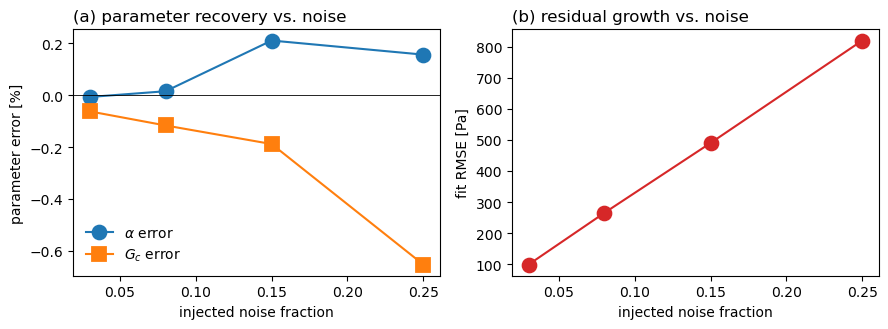

In [49]:
fig_n, axn = plt.subplots(1, 2, figsize=(9, 3.4))
nfs = [r["noise_frac"] for r in noise_rows]
axn[0].plot(nfs, [r["alpha_err_pct"] for r in noise_rows], "o-", ms=10, mew=1.3, label=r"$\alpha$ error")
axn[0].plot(nfs, [r["gc_err_pct"] for r in noise_rows], "s-", ms=10, mew=1.3, label=r"$G_c$ error")
axn[0].axhline(0, color="k", lw=0.6)
axn[0].set_xlabel("injected noise fraction"); axn[0].set_ylabel("parameter error [%]")
axn[0].legend(frameon=False); axn[0].set_title("(a) parameter recovery vs. noise", loc="left")

axn[1].plot(nfs, [r["rmse"] for r in noise_rows], "o-", ms=10, mew=1.3, color="tab:red")
axn[1].set_xlabel("injected noise fraction"); axn[1].set_ylabel("fit RMSE [Pa]")
axn[1].set_title("(b) residual growth vs. noise", loc="left")
fig_n.tight_layout()
fig_n.savefig("fig_noise_fmm.png", dpi=300, bbox_inches="tight")
fig_n.savefig("fig_noise_fmm.pdf", bbox_inches="tight")
plt.show()

## 10) Export noise-robustness macros + table

In [50]:
noise_macros = dict(
    fmmNoiseNLevels=len(NOISE_LEVELS),
    fmmNoiseMinLevel=f"{min(NOISE_LEVELS):.0%}".replace("%", r"\%"),
    fmmNoiseMaxLevel=f"{max(NOISE_LEVELS):.0%}".replace("%", r"\%"),
    fmmNoiseAlphaErrAtMax=pct(noise_rows[-1]["alpha_err_pct"]),
    fmmNoiseGcErrAtMax=pct(noise_rows[-1]["gc_err_pct"]),
    fmmNoiseRMSEAtMax=f"{noise_rows[-1]['rmse']:.4g}",
    fmmNoiseBICSelectedAtMax="true" if noise_rows[-1]["bic_selected_correct"] else "false",
    fmmNoiseBestModelAtMax=noise_rows[-1]["bic_best"],
    fmmNoiseBICEffChangedAtMax="true" if noise_rows[-1]["bic_eff_full_changed_conclusion"] else "false",
)
write_macros("results_fmm_noise.tex", noise_macros)

tbl_lines = [r"\begin{table}[t]", r"  \centering",
             r"  \caption{Parameter recovery and fit quality of the joint FMM "
             r"master-curve fit as a function of injected measurement noise "
             r"(synthetic proof of concept I, same configuration as "
             r"Table~\ref{tab:fmm_synthetic_ic} otherwise unchanged).}",
             r"  \label{tab:fmm_noise}", r"  \small",
             r"  \begin{tabular}{ccccc}", r"    \hline",
             r"    noise frac. & $\alpha$ err. & $G_c$ err. & RMSE [Pa] & $R^2$ \\",
             r"    \hline"]
for r in noise_rows:
    tbl_lines.append(f"    {r['noise_frac']:.0%}".replace("%", r"\%") + f" & {r['alpha_err_pct']:+.2f}\\% & "
                      f"{r['gc_err_pct']:+.2f}\\% & {fmt(r['rmse'],4)} & {r['r2']:.4f} \\\\")
tbl_lines += [r"    \hline", r"  \end{tabular}", r"\end{table}"]
write_table("table_fmm_noise.tex", "\n".join(tbl_lines))
print("\n".join(tbl_lines))

TypeError: 'str' object is not callable